# Citi Bike: Jersey City and Hoboken, September 2026
## Exploratory analysis for a bicycle redistribution project
This notebook asks: **where and when do observed bicycle flows create inventory pressure, and what OR project can this dataset support?**

Work through the cells in order. Each chart includes a reading guide and calculated observations. Tables and figures are exported to `output/citibike_eda/`.

**Three distinctions matter throughout:**
1. A completed trip is observed usage, not all potential demand. Unsuccessful rentals/returns are absent.
2. Arrivals minus departures is a change caused by observed customer trips, not actual stock. Initial inventories, staff redistribution, maintenance and station capacities are absent.
3. The station network is open. Trips can end outside Jersey City/Hoboken, and this file does not establish complete coverage of trips originating outside that area.

**Sources:** the supplied CSV supplies every empirical result. `Lecture4 DualitySensitivity.pdf` (slides 24–41), `Lecture5 LPCases.pdf`, `Lecture6 Network.pdf` (slides 17–29, 44–61), `Lecture7 IP.pdf` (slides 14–37, 63–79), `Lecture8 DP.pdf`, `Assignment_3.pdf` (Q1–2) and `Project_Guideline.pdf` guide the modeling discussion. [Citi Bike's official data description](https://citibikenyc.com/system-data), checked 13 November 2026, identifies the trip fields and points to GBFS station/status data. No external observations are merged into this EDA.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
from IPython import get_ipython
IN_IPYTHON = get_ipython() is not None
if IN_IPYTHON:
    get_ipython().run_line_magic('matplotlib', 'inline')
else:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GREEN, RED = '#2166ac', '#d97924', '#27806a', '#b64040'

DATA_NAME = 'JC-202609-citibike-tripdata.csv'
# Scripts resolve data beside this file; notebook cells also search the working directory.
search_start = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
ROOT = next((p for p in (search_start, *search_start.parents)
             if (p / DATA_NAME).exists()), None)
if ROOT is None:
    raise FileNotFoundError(f'Could not find {DATA_NAME} in {search_start} or its parents.')
SOURCE = ROOT / 'JC-202609-citibike-tripdata.csv'
if SOURCE.is_dir():
    candidates = [p for p in SOURCE.rglob('*.csv')
                  if '__MACOSX' not in p.parts and not p.name.startswith('._')]
    if len(candidates) != 1:
        raise ValueError(f'Expected one real CSV, found {len(candidates)}. Select explicitly.')
    SOURCE = candidates[0]
OUT = ROOT / 'output' / 'citibike_eda'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
MONTH_START, MONTH_END = pd.Timestamp('2026-09-01'), pd.Timestamp('2026-10-01')
DATES = pd.date_range(MONTH_START, MONTH_END, freq='D', inclusive='left')
HOURS = pd.date_range(MONTH_START, MONTH_END, freq='h', inclusive='left')
# Naive timestamps are analyzed as recorded local clock time. The CSV has no timezone metadata.
# No conversion to the analyst's Singapore timezone is performed.
LONG_RIDE_MINUTES = 24 * 60  # review flag, not an automatic deletion threshold
FAST_SPEED_KMH = 50         # diagnostic screening threshold, not proof of bad data
COORD_REVIEW_KM = 0.5       # station coordinate spread screening threshold
PERIOD_HOURS = {'Morning (07–09)': [7, 8, 9], 'Evening (16–18)': [16, 17, 18]}
DAY_ORDER = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

def say(text):
    if IN_IPYTHON:
        display(Markdown(text))
    else:
        # Windows terminals may not support every character used in the narrative.
        encoding = sys.stdout.encoding or 'utf-8'
        print(text.encode(encoding, errors='replace').decode(encoding))

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white')
    if IN_IPYTHON:
        plt.show()
    plt.close(fig)

def haversine(lat1, lon1, lat2, lon2):
    a1, o1, a2, o2 = [np.radians(np.asarray(v, dtype=float)) for v in (lat1, lon1, lat2, lon2)]
    a = np.sin((a2-a1)/2)**2 + np.cos(a1)*np.cos(a2)*np.sin((o2-o1)/2)**2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def table_export(frame, name, index=False):
    frame.to_csv(OUT / f'{name}.csv', index=index)
    return frame

raw = pd.read_csv(SOURCE, dtype='string', keep_default_na=False)
required_columns = {'ride_id', 'rideable_type', 'started_at', 'ended_at',
                    'start_station_name', 'start_station_id', 'end_station_name',
                    'end_station_id', 'start_lat', 'start_lng', 'end_lat',
                    'end_lng', 'member_casual'}
if not required_columns.issubset(raw.columns):
    raise ValueError(f'Missing source columns: {required_columns - set(raw.columns)}')
source_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
say(f'Loaded **{len(raw):,} rows and {raw.shape[1]} columns**. All fields are initially strings so station IDs such as `5114.08` remain identifiers. The raw CSV is never overwritten.')
display(raw.head())


Loaded **106,628 rows and 13 columns**. All fields are initially strings so station IDs such as `5114.08` remain identifiers. The raw CSV is never overwritten.

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,EFC244DEC104C0D9,electric_bike,2026-09-08 08:11:36.020,2026-09-08 08:28:50.409,Grand St,JC102,South End Ave & Albany St,5114.08,40.71517767732029,-74.03768330812454,40.709957,-74.016538,member
1,91862B808F2A4D6D,classic_bike,2026-09-15 08:37:23.253,2026-09-15 09:07:34.634,Hamilton Park,JC009,South End Ave & Albany St,5114.08,40.727595966,-74.044247311,40.709957,-74.016538,member
2,AF8084B80ED87657,classic_bike,2026-09-29 08:29:43.306,2026-09-29 09:00:49.776,Hamilton Park,JC009,South End Ave & Albany St,5114.08,40.727595966,-74.044247311,40.709957,-74.016538,member
3,C4500AE7EADAB74D,classic_bike,2026-09-18 19:29:50.583,2026-09-18 19:37:53.218,Morris Canal,JC072,Van Vorst Park,JC035,40.7124188237569,-74.03852552175522,40.71848892,-74.047726625,member
4,4512BCC0A11E0C48,classic_bike,2026-09-28 08:18:01.287,2026-09-28 08:26:01.593,Morris Canal,JC072,Van Vorst Park,JC035,40.7124188237569,-74.03852552175522,40.71848892,-74.047726625,member


## 1. Missing values, duplicates and data types
Empty strings and whitespace count as missing. We inspect each column before choosing any cleaning action. Missing end stations should not cause us to discard otherwise usable departure observations.

,column,raw_dtype,missing_count,missing_pct,unique_nonmissing,whitespace_changed
0,ride_id,string,0,0.000000,106628,0
1,rideable_type,string,0,0.000000,2,0
2,started_at,string,0,0.000000,106625,0
3,ended_at,string,0,0.000000,106560,0
4,start_station_name,string,0,0.000000,108,0
5,start_station_id,string,0,0.000000,108,0
6,end_station_name,string,284,0.266347,222,0
7,end_station_id,string,333,0.312301,222,0
8,start_lat,string,0,0.000000,108,0
9,start_lng,string,0,0.000000,108,0


Exact duplicate rows: **0**. Rows with repeated nonblank ride IDs before deduplication: **0**. Conflicting ride IDs after exact deduplication: **0**.

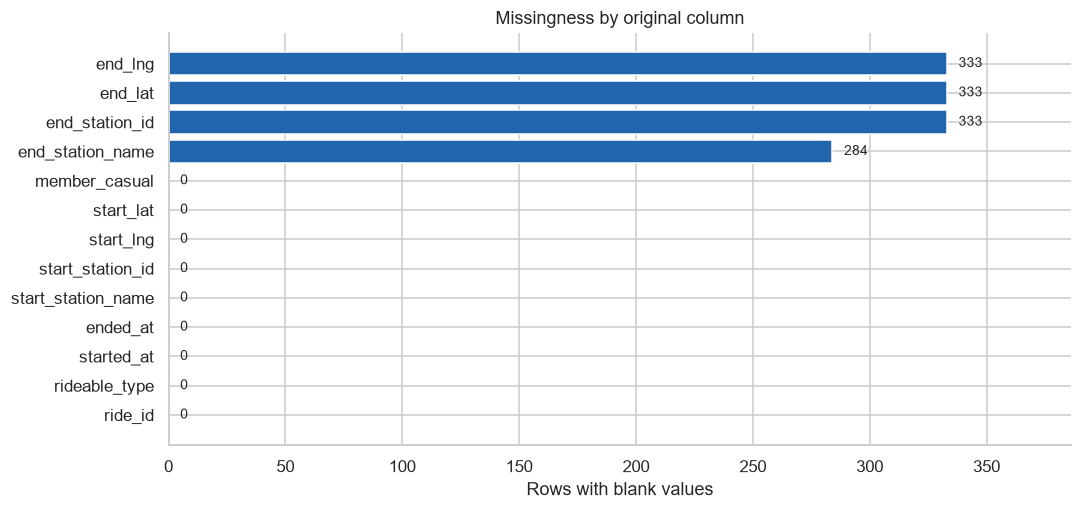

In [2]:
df = raw.apply(lambda col: col.str.strip()).replace('', pd.NA)
quality = pd.DataFrame({
    'column': raw.columns,
    'raw_dtype': [str(raw[c].dtype) for c in raw],
    'missing_count': [int(df[c].isna().sum()) for c in df],
    'missing_pct': [100*df[c].isna().mean() for c in df],
    'unique_nonmissing': [df[c].nunique() for c in df],
    'whitespace_changed': [(raw[c] != raw[c].str.strip()).sum() for c in raw],
})
table_export(quality, 'data_quality')
display(quality)
exact_duplicates = int(df.duplicated().sum())
duplicate_id_rows = df['ride_id'].notna() & df['ride_id'].duplicated(keep=False)
# Remove identical duplicate rows only. Conflicting records for the same ID are quarantined.
dedup = df.drop_duplicates().copy()
conflict_ids = set(dedup.loc[dedup['ride_id'].notna() & dedup['ride_id'].duplicated(False), 'ride_id'])
say(f'Exact duplicate rows: **{exact_duplicates:,}**. Rows with repeated nonblank ride IDs before deduplication: **{int(duplicate_id_rows.sum()):,}**. Conflicting ride IDs after exact deduplication: **{len(conflict_ids):,}**.')
fig, ax = plt.subplots(figsize=(10, 4.8))
q = quality.sort_values('missing_count')
ax.barh(q['column'], q['missing_count'], color=BLUE)
for i, n in enumerate(q['missing_count']):
    ax.text(n + max(quality['missing_count'].max(), 1)*0.015, i, f'{n:,}', va='center', fontsize=9)
ax.set(xlabel='Rows with blank values', title='Missingness by original column')
ax.set_xlim(0, max(quality['missing_count'].max(), 1)*1.16)
savefig(fig, '01_missing_values')

## 2. Parsing and an auditable cleaning policy
- Parse timestamps and numeric coordinates, keeping station IDs as strings.
- Flag impossible/missing times and nonpositive durations. Exclude those from event analysis.
- Filter **September starts** for trip-demand charts. Keep **September arrivals** from August starts in the separate event view.
- Recover missing station IDs only if the exact station name maps to exactly one observed ID. Record every recovery; otherwise leave unresolved. No nearest-station guesses.
- Use the most frequent observed name as a display label for each ID. Preserve aliases.
- Retain long trips in the main flow analysis and show a sensitivity comparison. Flagging is different from deleting.
- Use observed coordinates only. Coordinate gaps do not invalidate known station events, and coordinates are not silently imputed.

In [3]:
df = dedup.copy()
for c in ['started_at', 'ended_at']:
    df[c + '_parsed'] = pd.to_datetime(df[c], format='mixed', errors='coerce')
for c in ['start_lat', 'start_lng', 'end_lat', 'end_lng']:
    df[c + '_numeric'] = pd.to_numeric(df[c], errors='coerce')
df['duration_min'] = (df['ended_at_parsed'] - df['started_at_parsed']).dt.total_seconds()/60
df['flag_bad_time'] = df[['started_at_parsed', 'ended_at_parsed']].isna().any(axis=1)
df['flag_nonpositive_duration'] = df['duration_min'].le(0).fillna(False)
df['flag_long_ride'] = df['duration_min'].gt(LONG_RIDE_MINUTES).fillna(False)
df['flag_short_ride'] = df['duration_min'].between(0, 1, inclusive='neither').fillna(False)
df['flag_conflicting_id'] = df['ride_id'].isin(conflict_ids)
df['flag_missing_ride_id'] = df['ride_id'].isna()
df['start_in_month'] = df['started_at_parsed'].ge(MONTH_START) & df['started_at_parsed'].lt(MONTH_END)
df['end_in_month'] = df['ended_at_parsed'].ge(MONTH_START) & df['ended_at_parsed'].lt(MONTH_END)

endpoint_parts = []
for side in ['start', 'end']:
    part = df[[f'{side}_station_id', f'{side}_station_name', f'{side}_lat_numeric', f'{side}_lng_numeric']].copy()
    part.columns = ['station_id', 'station_name', 'lat', 'lng']
    part['side'] = side
    endpoint_parts.append(part)
endpoints = pd.concat(endpoint_parts, ignore_index=True)
pairs = endpoints[['station_name', 'station_id']].dropna().drop_duplicates()
name_counts = pairs.groupby('station_name')['station_id'].nunique()
unique_names = name_counts[name_counts.eq(1)].index
name_to_id = pairs[pairs['station_name'].isin(unique_names)].set_index('station_name')['station_id']
for side in ['start', 'end']:
    original = df[f'{side}_station_id']
    inferred = df[f'{side}_station_name'].map(name_to_id)
    df[f'{side}_station_id_resolved'] = original.fillna(inferred)
    df[f'{side}_id_recovered'] = original.isna() & inferred.notna()
    lat, lng = df[f'{side}_lat_numeric'], df[f'{side}_lng_numeric']
    df[f'flag_{side}_coord_missing'] = lat.isna() | lng.isna()
    df[f'flag_{side}_coord_invalid'] = ((lat.notna() & ~lat.between(-90, 90)) |
                                                (lng.notna() & ~lng.between(-180, 180)))
    df[f'flag_{side}_coord_parse_error'] = ((df[f'{side}_lat'].notna() & lat.isna()) |
                                                     (df[f'{side}_lng'].notna() & lng.isna()))

name_freq = endpoints.dropna(subset=['station_id', 'station_name']).groupby(['station_id', 'station_name']).size().rename('n').reset_index()
canonical_names = (name_freq.sort_values(['n', 'station_name'], ascending=[False, True])
                   .drop_duplicates('station_id').set_index('station_id')['station_name'])
station_aliases = (pairs.groupby('station_id')['station_name'].agg(lambda s: '; '.join(sorted(s.unique())))
                   .rename('observed_names').to_frame())
station_aliases['number_of_names'] = pairs.groupby('station_id')['station_name'].nunique()
station_aliases['canonical_name'] = canonical_names
table_export(station_aliases.reset_index(), 'station_name_aliases')
name_id_ambiguities = pairs[pairs['station_name'].isin(name_counts[name_counts.gt(1)].index)]
table_export(name_id_ambiguities, 'ambiguous_station_names')

valid_coords = ~(df['flag_start_coord_missing'] | df['flag_end_coord_missing'] |
                 df['flag_start_coord_invalid'] | df['flag_end_coord_invalid'])
df['straight_line_km'] = np.nan
df.loc[valid_coords, 'straight_line_km'] = haversine(
    df.loc[valid_coords, 'start_lat_numeric'], df.loc[valid_coords, 'start_lng_numeric'],
    df.loc[valid_coords, 'end_lat_numeric'], df.loc[valid_coords, 'end_lng_numeric'])
df['straight_line_speed_kmh'] = df['straight_line_km']/(df['duration_min']/60)
df['flag_fast_straight_line_speed'] = df['straight_line_speed_kmh'].gt(FAST_SPEED_KMH).fillna(False)
valid_trip = ~(df['flag_bad_time'] | df['flag_nonpositive_duration'] |
               df['flag_conflicting_id'] | df['flag_missing_ride_id'])
trips = df.loc[valid_trip & df['start_in_month']].copy()
trips['date'] = trips['started_at_parsed'].dt.normalize()
trips['hour'] = trips['started_at_parsed'].dt.hour
trips['weekday'] = trips['started_at_parsed'].dt.day_name()
trips['day_type'] = np.where(trips['started_at_parsed'].dt.day_of_week < 5, 'Weekday', 'Weekend')
trips['same_station'] = (trips['start_station_id_resolved'].eq(trips['end_station_id_resolved']) &
                          trips['end_station_id_resolved'].notna()).fillna(False)
# A data-defined service domain: all observed JC/HB origin IDs, not an inferred city polygon.
origin_ids = set(df.loc[df['start_station_id'].notna(), 'start_station_id'])
LOCAL = sorted(s for s in origin_ids if s.startswith(('JC', 'HB')))
if not LOCAL:
    raise ValueError('No JC/HB origins found; review the intended service domain.')
trips['destination_group'] = np.select(
    [trips['end_station_id_resolved'].isna(), trips['end_station_id_resolved'].isin(LOCAL)],
    ['Unresolved', 'Within service domain'], default='Outside service domain')

cleaning_audit = pd.DataFrame([
    ('Raw records', len(raw)), ('Exact duplicate rows removed', exact_duplicates),
    ('Invalid/conflicting/missing-ID records excluded from time analysis', int((~valid_trip).sum())),
    ('Unparseable or missing timestamps', int(df['flag_bad_time'].sum())),
    ('Nonpositive trip durations', int(df['flag_nonpositive_duration'].sum())),
    ('Coordinate strings that fail numeric parsing', int((df['flag_start_coord_parse_error'] | df['flag_end_coord_parse_error']).sum())),
    ('Invalid latitude/longitude ranges', int((df['flag_start_coord_invalid'] | df['flag_end_coord_invalid']).sum())),
    ('Valid September departures', len(trips)),
    ('Valid starts outside September', int((valid_trip & ~df['start_in_month']).sum())),
    ('Valid September arrivals from pre-month starts', int((valid_trip & ~df['start_in_month'] & df['end_in_month']).sum())),
    ('Missing destination IDs before recovery', int(df['end_station_id'].isna().sum())),
    ('Destination IDs recovered by unique exact name', int(df['end_id_recovered'].sum())),
    ('Destination IDs still unresolved', int(df['end_station_id_resolved'].isna().sum())),
    ('Trips over 24 hours retained and flagged', int(df['flag_long_ride'].sum())),
    ('Trips under one minute flagged', int(df['flag_short_ride'].sum())),
    ('Straight-line speed over 50 km/h flagged', int(df['flag_fast_straight_line_speed'].sum())),
    ('Station IDs with multiple observed names', int(station_aliases['number_of_names'].gt(1).sum())),
    ('Station names mapping to multiple IDs', int(name_counts.gt(1).sum())),
], columns=['check', 'count'])
display(table_export(cleaning_audit, 'cleaning_audit'))
flag_cols = [c for c in df if c.startswith('flag_')]
flagged = df[flag_cols].any(axis=1) | ~df['start_in_month'] | df['end_station_id_resolved'].isna() | df['end_id_recovered']
table_export(df.loc[flagged], 'flagged_records')
table_export(trips, 'cleaned_september_trips')
say(f'**Cleaning result:** {len(trips):,} September-start trips. Recovered {int(df["end_id_recovered"].sum()):,} missing end IDs by unique exact-name matches; {int(df["end_station_id_resolved"].isna().sum()):,} remain unresolved. These recoveries are explicit assumptions, not new observations. Long trips remain in the main event analysis.')

,check,count
0,Raw records,106628
1,Exact duplicate rows removed,0
2,Invalid/conflicting/missing-ID records excluded from tim...,0
3,Unparseable or missing timestamps,0
4,Nonpositive trip durations,0
5,Coordinate strings that fail numeric parsing,0
6,Invalid latitude/longitude ranges,0
7,Valid September departures,106617
8,Valid starts outside September,11
9,Valid September arrivals from pre-month starts,11


**Cleaning result:** 106,617 September-start trips. Recovered 49 missing end IDs by unique exact-name matches; 284 remain unresolved. These recoveries are explicit assumptions, not new observations. Long trips remain in the main event analysis.

## 3. When are bicycles used?
Daily totals expose unusual days. Compare **average trips per day** by day type/hour, since September contains different numbers of weekdays and weekend days. Calendar weekday is not a verified commuting purpose, and a low-usage date is not automatically a bad-data date.

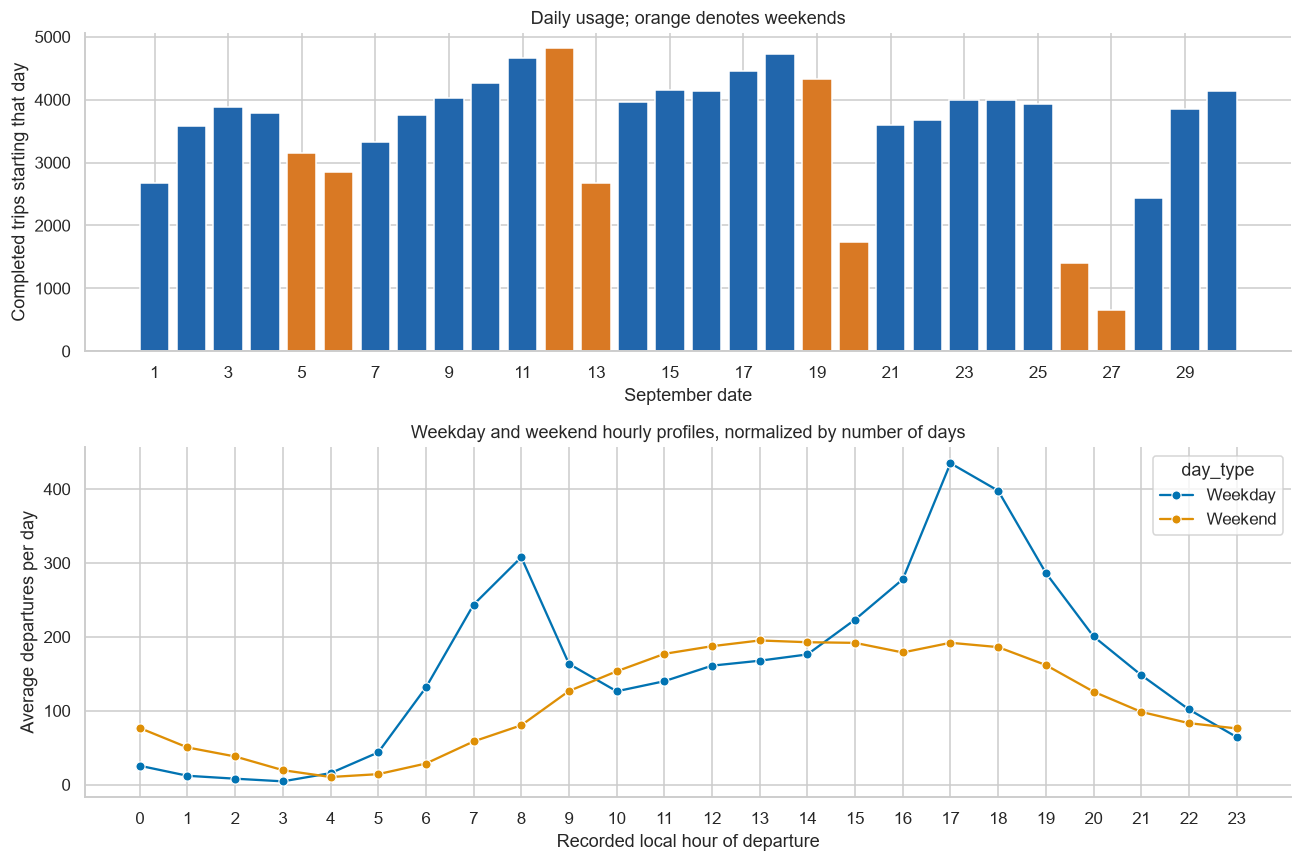

**Read the pattern:** the three busiest average weekday hours are 17:00, 18:00, 08:00. The weekend peak is 13:00. The lowest daily count is **652** on **27 Sep**, versus a maximum of **4,817** on **12 Sep**. Investigate weather, outages, calendar effects and data coverage before assigning a cause or deleting these dates.

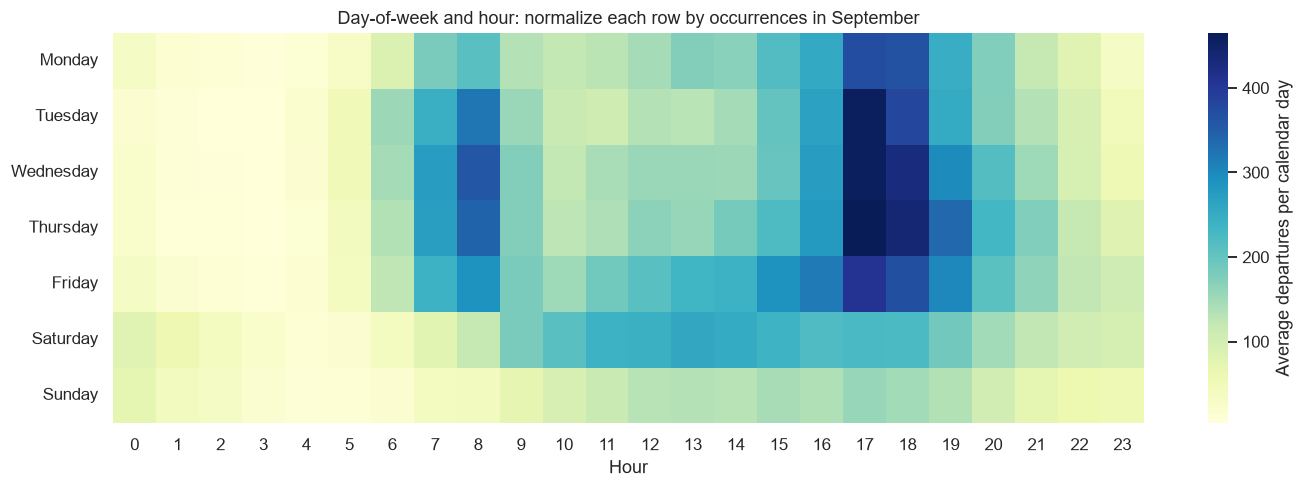

In [4]:
daily = trips.groupby('date').size().reindex(DATES, fill_value=0).rename('departures').to_frame()
daily.index.name = 'date'
daily['day_type'] = np.where(daily.index.day_of_week < 5, 'Weekday', 'Weekend')
day_counts = pd.Series(np.where(DATES.day_of_week < 5, 'Weekday', 'Weekend')).value_counts()
hour_profile = (trips.groupby(['day_type', 'hour']).size()
                .reindex(pd.MultiIndex.from_product([['Weekday', 'Weekend'], range(24)], names=['day_type', 'hour']), fill_value=0)
                .rename('trips').reset_index())
hour_profile['average_trips_per_day'] = hour_profile['trips']/hour_profile['day_type'].map(day_counts)
table_export(daily.reset_index(), 'daily_trips')
table_export(hour_profile, 'hourly_usage_profile')
fig, axes = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [1, 1.1]})
axes[0].bar(daily.index.day, daily['departures'], color=np.where(daily['day_type'].eq('Weekday'), BLUE, ORANGE))
axes[0].set(xlabel='September date', ylabel='Completed trips starting that day', title='Daily usage; orange denotes weekends')
axes[0].set_xticks(range(1, 31, 2))
sns.lineplot(data=hour_profile, x='hour', y='average_trips_per_day', hue='day_type',
             hue_order=['Weekday', 'Weekend'], marker='o', ax=axes[1])
axes[1].set(xlabel='Recorded local hour of departure', ylabel='Average departures per day', title='Weekday and weekend hourly profiles, normalized by number of days')
axes[1].set_xticks(range(0, 24))
savefig(fig, '02_daily_and_hourly_usage')
weekday_peak = hour_profile.loc[hour_profile['day_type'].eq('Weekday')].nlargest(3, 'average_trips_per_day')
weekend_peak = hour_profile.loc[hour_profile['day_type'].eq('Weekend')].nlargest(1, 'average_trips_per_day')
say(f'**Read the pattern:** the three busiest average weekday hours are {", ".join(f"{int(h):02d}:00" for h in weekday_peak["hour"])}. The weekend peak is {int(weekend_peak.iloc[0]["hour"]):02d}:00. The lowest daily count is **{daily["departures"].min():,}** on **{daily["departures"].idxmin():%d %b}**, versus a maximum of **{daily["departures"].max():,}** on **{daily["departures"].idxmax():%d %b}**. Investigate weather, outages, calendar effects and data coverage before assigning a cause or deleting these dates.')
heat = pd.crosstab(trips['weekday'], trips['hour']).reindex(index=DAY_ORDER, columns=range(24), fill_value=0)
weekday_occurrences = pd.Series(DATES.day_name()).value_counts()
heat = heat.div(weekday_occurrences.reindex(DAY_ORDER), axis=0)
fig, ax = plt.subplots(figsize=(13, 4.6))
sns.heatmap(heat, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Average departures per calendar day'})
ax.set(xlabel='Hour', ylabel='', title='Day-of-week and hour: normalize each row by occurrences in September')
savefig(fig, '03_day_hour_heatmap')

## 4. Rider mix, bicycle types, duration and distance
Compare members/casual riders and classic/electric bicycles. Duration is right-skewed, so show medians and a readable main-range histogram plus a tail panel. Straight-line distance is a geographic lower bound, not a road distance or truck travel time. Same-station rides can be genuine round trips.

,rideable_type,member_casual,trips
0,classic_bike,casual,8915
1,classic_bike,member,34098
2,electric_bike,casual,18914
3,electric_bike,member,44690


,rideable_type,member_casual,trips,median,mean,p95,p99
0,classic_bike,casual,8915,10.388983,23.278730,56.959327,149.979164
1,classic_bike,member,34098,6.017525,9.694293,23.748012,47.472465
2,electric_bike,casual,18914,7.443408,11.168566,29.205493,71.217016
3,electric_bike,member,44690,5.780508,7.612042,17.867581,40.297534


,destination_quality,trips,median_duration_min,over_24_hours,over_24_hours_share
0,End ID present in source,106286,6.390817,1,0.000009
1,End ID recovered by exact name,49,5.486050,0,0.000000
2,Unresolved end ID,282,64.079942,35,0.124113


**Missingness and outliers are related:** 35 of the 36 September-start trips over 24 hours also have unresolved destination IDs. Inspect the table before using complete-case deletion: it changes the duration distribution. This association does not identify why a record is incomplete.

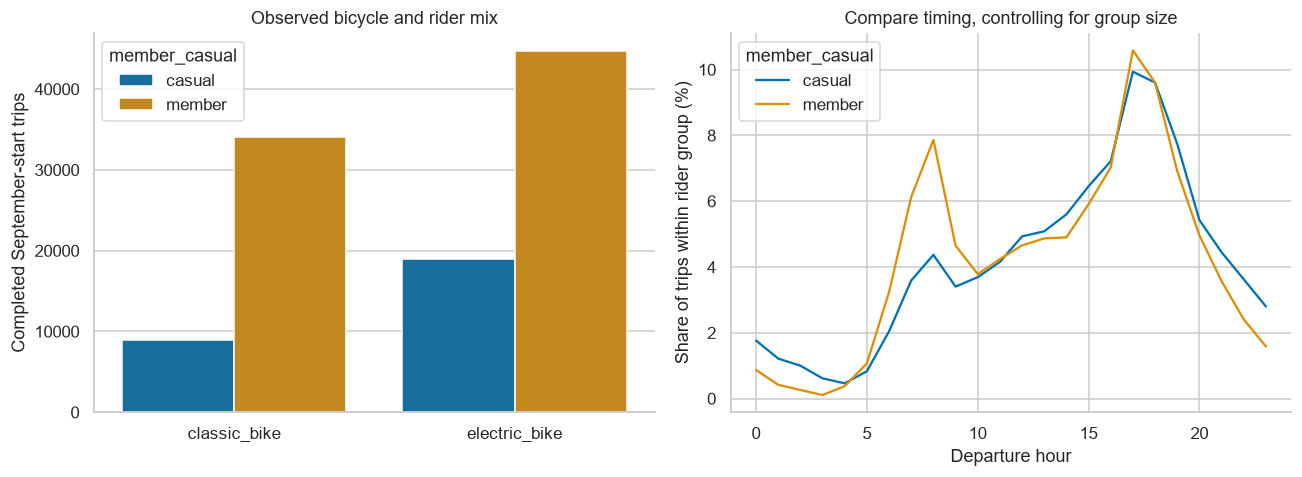

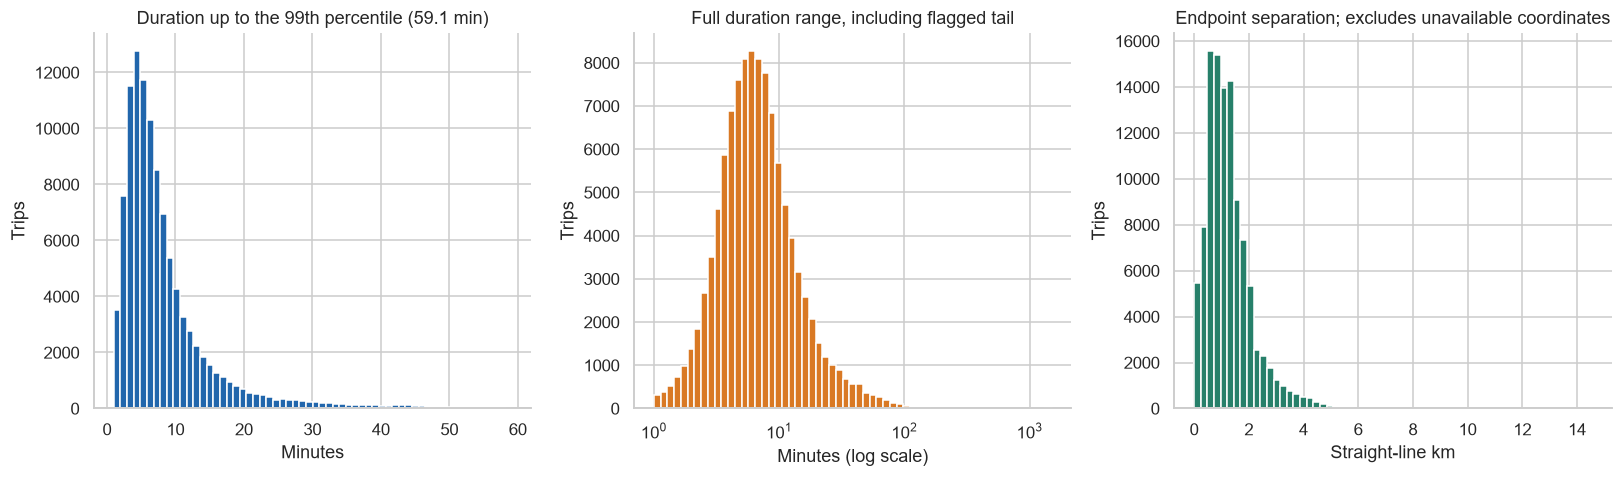

Members account for **73.9%** and electric bicycles for **59.7%** of valid September starts. Median duration is **6.40 minutes**; the 95th percentile is **25.38 minutes**. **3,853** trips return to their origin station. Keep bicycle type available for an optional extension; electrics may need different operating assumptions that this CSV cannot establish.

In [5]:
mix = trips.groupby(['rideable_type', 'member_casual'], dropna=False).size().rename('trips').reset_index()
display(table_export(mix, 'rider_bicycle_mix'))
duration_summary = trips.groupby(['rideable_type', 'member_casual'])['duration_min'].agg(
    trips='size', median='median', mean='mean', p95=lambda s: s.quantile(.95), p99=lambda s: s.quantile(.99))
display(table_export(duration_summary.reset_index(), 'duration_summary'))
destination_quality = np.select(
    [trips['end_station_id_resolved'].isna(), trips['end_id_recovered']],
    ['Unresolved end ID', 'End ID recovered by exact name'], default='End ID present in source')
duration_by_quality = (trips.assign(destination_quality=destination_quality)
    .groupby('destination_quality').agg(trips=('ride_id', 'size'),
        median_duration_min=('duration_min', 'median'),
        over_24_hours=('flag_long_ride', 'sum'),
        over_24_hours_share=('flag_long_ride', 'mean')).reset_index())
display(table_export(duration_by_quality, 'duration_by_destination_quality'))
long_unresolved = int((trips['flag_long_ride'] & trips['end_station_id_resolved'].isna()).sum())
say(f'**Missingness and outliers are related:** {long_unresolved} of the {int(trips["flag_long_ride"].sum())} September-start trips over 24 hours also have unresolved destination IDs. Inspect the table before using complete-case deletion: it changes the duration distribution. This association does not identify why a record is incomplete.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=mix, x='rideable_type', y='trips', hue='member_casual', ax=axes[0])
axes[0].set(xlabel='', ylabel='Completed September-start trips', title='Observed bicycle and rider mix')
type_hour = trips.groupby(['member_casual', 'hour']).size().rename('n').reset_index()
type_hour['share_of_rider_group_pct'] = 100*type_hour['n']/type_hour.groupby('member_casual')['n'].transform('sum')
sns.lineplot(data=type_hour, x='hour', y='share_of_rider_group_pct', hue='member_casual', ax=axes[1])
axes[1].set(xlabel='Departure hour', ylabel='Share of trips within rider group (%)', title='Compare timing, controlling for group size')
savefig(fig, '04_rider_and_bicycle_mix')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
upper = float(trips['duration_min'].quantile(.99))
axes[0].hist(trips.loc[trips['duration_min'].le(upper), 'duration_min'], bins=60, color=BLUE)
axes[0].set(xlabel='Minutes', ylabel='Trips', title=f'Duration up to the 99th percentile ({upper:.1f} min)')
axes[1].hist(trips['duration_min'], bins=np.geomspace(max(trips['duration_min'].min(), .01), trips['duration_min'].max(), 60), color=ORANGE)
axes[1].set_xscale('log')
axes[1].set(xlabel='Minutes (log scale)', ylabel='Trips', title='Full duration range, including flagged tail')
axes[2].hist(trips['straight_line_km'].dropna(), bins=60, color=GREEN)
axes[2].set(xlabel='Straight-line km', ylabel='Trips', title='Endpoint separation; excludes unavailable coordinates')
savefig(fig, '05_duration_and_distance')
member_share = 100*trips['member_casual'].eq('member').mean()
electric_share = 100*trips['rideable_type'].eq('electric_bike').mean()
say(f'Members account for **{member_share:.1f}%** and electric bicycles for **{electric_share:.1f}%** of valid September starts. Median duration is **{trips["duration_min"].median():.2f} minutes**; the 95th percentile is **{trips["duration_min"].quantile(.95):.2f} minutes**. **{int(trips["same_station"].sum()):,}** trips return to their origin station. Keep bicycle type available for an optional extension; electrics may need different operating assumptions that this CSV cannot establish.')

## 5. Define the service domain and construct station events
Trip charts use September departure dates. Station inventory changes use **departure times for outflows and arrival times for inflows**, separately clipped to September. An August-start trip arriving in September contributes a September arrival. A missing destination still contributes its valid departure.

The service domain is the observed JC/HB origin station set. Outside-domain destinations are retained in the overall data and reported as boundary flows. We do not force Manhattan stations into a closed Jersey City optimization model.

In [6]:
def make_events(frame):
    parts = []
    for side, event, delta in [('start', 'departure', -1), ('end', 'arrival', 1)]:
        time_col = 'started_at_parsed' if side == 'start' else 'ended_at_parsed'
        mask = frame[time_col].ge(MONTH_START) & frame[time_col].lt(MONTH_END)
        part = frame.loc[mask, ['ride_id', f'{side}_station_id_resolved', time_col, 'rideable_type', 'member_casual']].copy()
        part.columns = ['ride_id', 'station_id', 'time', 'rideable_type', 'member_casual']
        part['event'], part['delta'] = event, delta
        parts.append(part)
    events = pd.concat(parts, ignore_index=True)
    events['hour_start'] = events['time'].dt.floor('h')
    events['date'] = events['time'].dt.normalize()
    events['hour'] = events['time'].dt.hour
    events['day_type'] = np.where(events['time'].dt.day_of_week < 5, 'Weekday', 'Weekend')
    return events

events = make_events(df.loc[valid_trip])
events['domain'] = np.select([events['station_id'].isna(), events['station_id'].isin(LOCAL)],
                              ['Unresolved', 'Service domain'], default='Outside service domain')
boundary = pd.crosstab(events['domain'], events['event']).reindex(columns=['departure', 'arrival'], fill_value=0)
display(table_export(boundary.reset_index(), 'endpoint_domain_counts'))
local_events = events[events['station_id'].isin(LOCAL)].copy()
grid = pd.MultiIndex.from_product([LOCAL, HOURS], names=['station_id', 'hour_start'])
station_hourly = (local_events.groupby(['station_id', 'hour_start', 'event']).size().unstack('event', fill_value=0)
                  .reindex(grid, fill_value=0).reindex(columns=['departure', 'arrival'], fill_value=0))
station_hourly = station_hourly.rename(columns={'departure': 'departures', 'arrival': 'arrivals'}).reset_index()
station_hourly.columns.name = None
station_hourly['net_inflow'] = station_hourly['arrivals'] - station_hourly['departures']
station_hourly['date'] = station_hourly['hour_start'].dt.normalize()
station_hourly['hour'] = station_hourly['hour_start'].dt.hour
station_hourly['day_type'] = np.where(station_hourly['hour_start'].dt.day_of_week < 5, 'Weekday', 'Weekend')
station_hourly['station_name'] = station_hourly['station_id'].map(canonical_names).fillna(station_hourly['station_id'])
station_hourly['city_from_id'] = np.where(station_hourly['station_id'].str.startswith('JC'), 'Jersey City', 'Hoboken')
table_export(station_hourly, 'station_hourly_observed_flows')
station_stats = station_hourly.groupby('station_id')[['departures', 'arrivals', 'net_inflow']].sum()
station_stats['total_activity'] = station_stats['departures'] + station_stats['arrivals']
station_stats['imbalance_ratio'] = station_stats['net_inflow']/station_stats['total_activity'].replace(0, np.nan)
station_stats['station_name'] = station_stats.index.map(canonical_names)
coords = endpoints.dropna(subset=['station_id', 'lat', 'lng']).copy()
coords = coords[coords['lat'].between(-90, 90) & coords['lng'].between(-180, 180)]
station_coords = coords.groupby('station_id')[['lat', 'lng']].median()
station_stats = station_stats.join(station_coords)
coords = coords.join(station_coords.rename(columns={'lat': 'median_lat', 'lng': 'median_lng'}), on='station_id')
coords['distance_to_median_km'] = haversine(coords['lat'], coords['lng'], coords['median_lat'], coords['median_lng'])
coordinate_spread = coords.groupby('station_id')['distance_to_median_km'].agg(
    observations='size', median_km='median', p95_km=lambda s: s.quantile(.95), max_km='max')
coordinate_spread['review_p95_over_500m'] = coordinate_spread['p95_km'].gt(COORD_REVIEW_KM)
display(table_export(coordinate_spread[coordinate_spread['review_p95_over_500m']].reset_index(), 'stations_for_coordinate_review'))
table_export(coordinate_spread.reset_index(), 'station_coordinate_spread')
table_export(station_stats.reset_index(), 'station_summary')
outside_count = int(boundary.loc['Outside service domain', 'arrival']) if 'Outside service domain' in boundary.index else 0
say(f'Observed origins: **{df["start_station_id"].nunique()}** unique IDs; observed destinations: **{df["end_station_id"].nunique()}** unique IDs; union: **{endpoints["station_id"].nunique()}**. The modeled service domain has **{len(LOCAL)} stations**. September endpoint counts include **{outside_count:,} outside-domain arrivals**. The grid includes zero-activity hours: **{len(station_hourly):,} station-hours**. These zeros mean no recorded events, not proven zero latent demand or confirmed station availability.')

event,domain,departure,arrival
0,Outside service domain,0,274
1,Service domain,106617,106070
2,Unresolved,0,284


,station_id,observations,median_km,p95_km,max_km,review_p95_over_500m


Observed origins: **108** unique IDs; observed destinations: **222** unique IDs; union: **222**. The modeled service domain has **108 stations**. September endpoint counts include **274 outside-domain arrivals**. The grid includes zero-activity hours: **77,760 station-hours**. These zeros mean no recorded events, not proven zero latent demand or confirmed station availability.

## 6. Which stations accumulate or lose bicycles through customer trips?
Positive net inflow means customer trips add bicycles; negative means they remove bicycles. Use both volume and net flow. A busy station can have a near-zero monthly balance and still need several intraday interventions. Labels include station IDs to avoid name ambiguity.

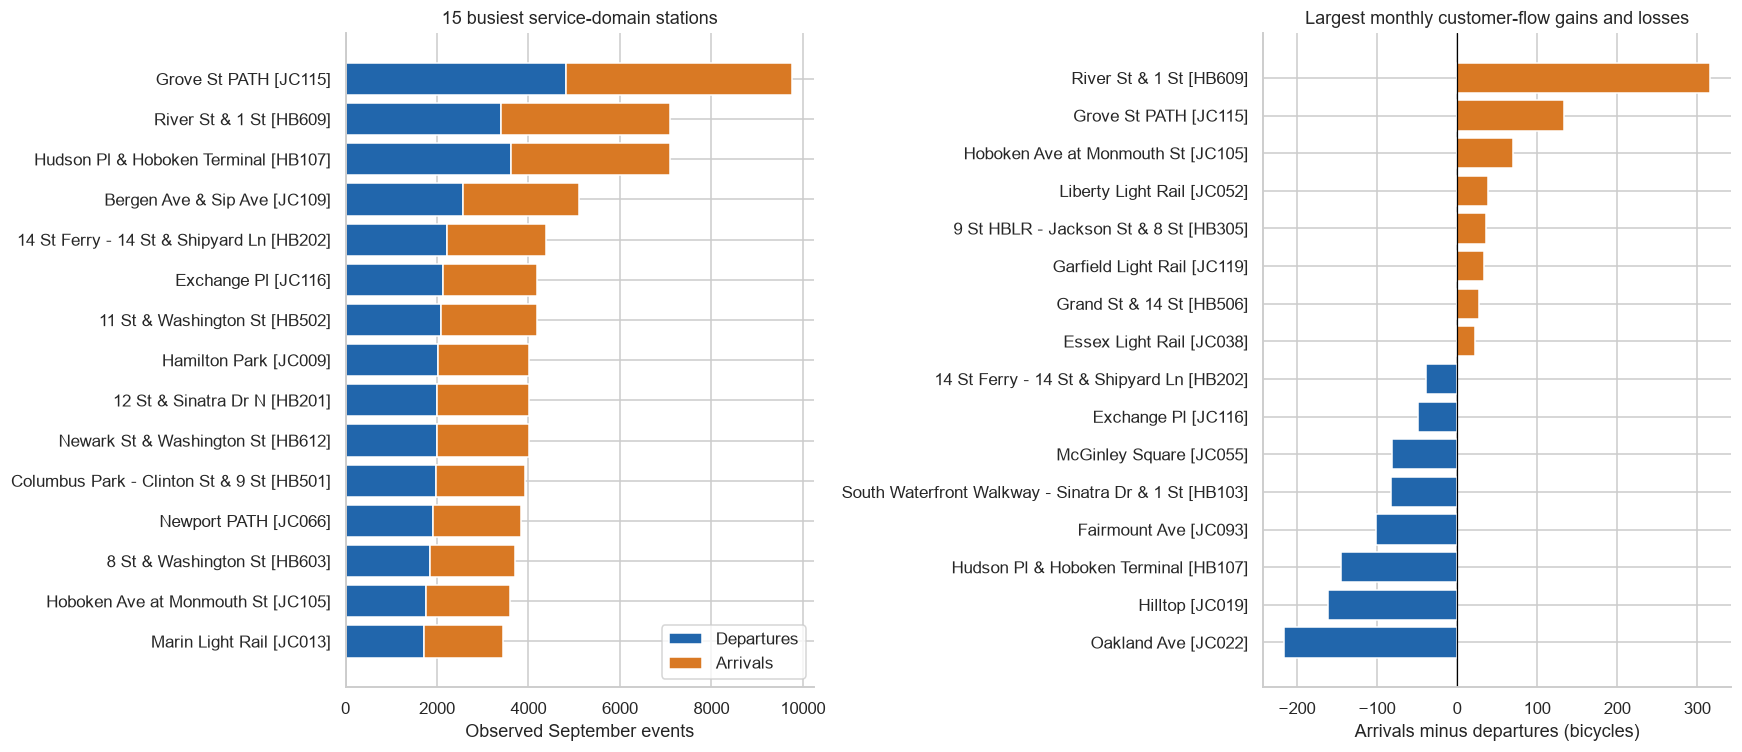

,station_name,departures,arrivals,net_inflow
station_id,,,,
JC022,Oakland Ave,776,560,-216
JC019,Hilltop,854,693,-161
HB107,Hudson Pl & Hoboken Terminal,3623,3478,-145
JC093,Fairmount Ave,585,484,-101
HB103,South Waterfront Walkway - Sinatra Dr & 1 St,1613,1531,-82
JC055,McGinley Square,1093,1012,-81
JC116,Exchange Pl,2121,2072,-49
HB202,14 St Ferry - 14 St & Shipyard Ln,2216,2177,-39


,station_name,departures,arrivals,net_inflow
station_id,,,,
HB609,River St & 1 St,3394,3710,316
JC115,Grove St PATH,4810,4944,134
JC105,Hoboken Ave at Monmouth St,1763,1833,70
JC052,Liberty Light Rail,1294,1332,38
HB305,9 St HBLR - Jackson St & 8 St,1535,1571,36
JC119,Garfield Light Rail,179,213,34
HB506,Grand St & 14 St,1120,1147,27
JC097,York St & Marin Blvd,595,617,22


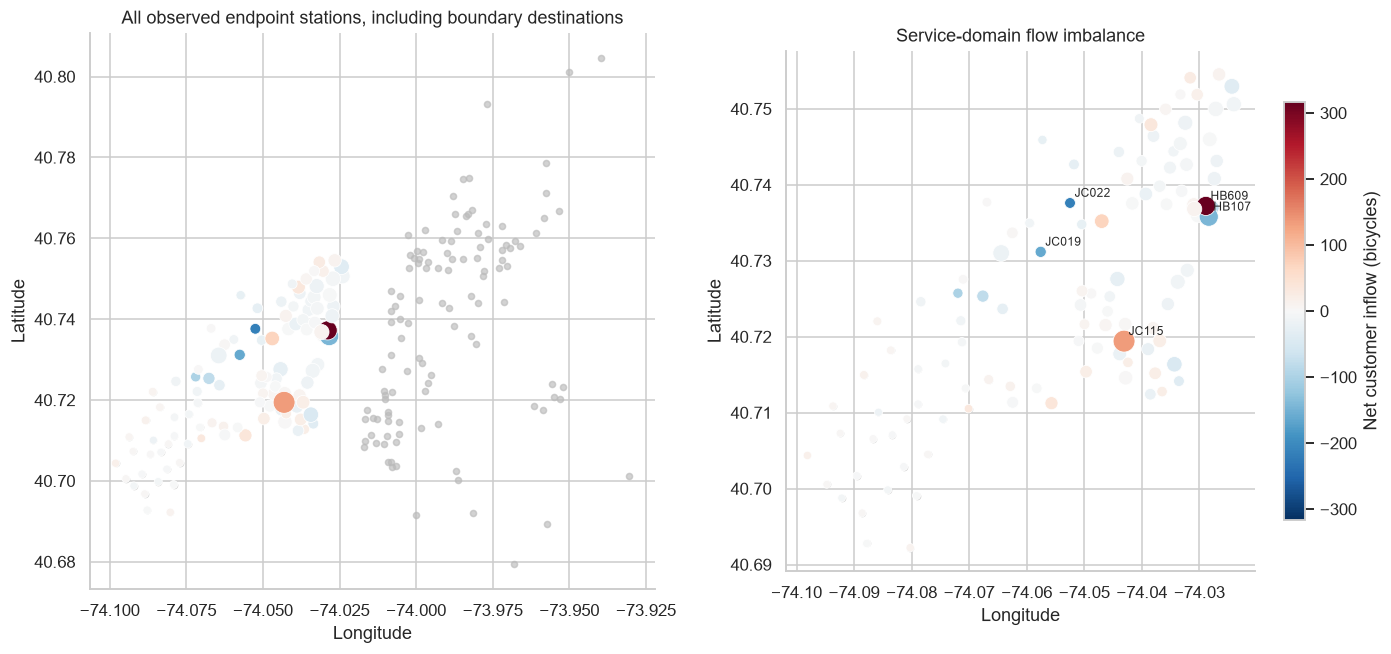

**Interpretation:** blue stations have net customer outflows and red stations have net customer inflows. Size represents total activity. The map uses median observed station coordinates and has no road-network basemap. It does not imply that an operator can drive directly across the river or use straight-line travel distances.

In [7]:
def station_label(ids):
    return [f'{canonical_names.get(i, i)} [{i}]' for i in ids]

top = station_stats.nlargest(15, 'total_activity').sort_values('total_activity')
extremes = pd.concat([station_stats.nsmallest(8, 'net_inflow'), station_stats.nlargest(8, 'net_inflow')]).drop_duplicates().sort_values('net_inflow')
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(station_label(top.index), top['departures'], label='Departures', color=BLUE)
axes[0].barh(station_label(top.index), top['arrivals'], left=top['departures'], label='Arrivals', color=ORANGE)
axes[0].set(xlabel='Observed September events', title='15 busiest service-domain stations')
axes[0].legend()
axes[1].barh(station_label(extremes.index), extremes['net_inflow'], color=np.where(extremes['net_inflow'].ge(0), ORANGE, BLUE))
axes[1].axvline(0, color='black', linewidth=.8)
axes[1].set(xlabel='Arrivals minus departures (bicycles)', title='Largest monthly customer-flow gains and losses')
savefig(fig, '06_station_activity_and_balance')
display(station_stats.sort_values('net_inflow')[['station_name', 'departures', 'arrivals', 'net_inflow']].head(8))
display(station_stats.sort_values('net_inflow', ascending=False)[['station_name', 'departures', 'arrivals', 'net_inflow']].head(8))
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
vmax = max(station_stats['net_inflow'].abs().max(), 1)
for ax, title, limits in [(axes[0], 'All observed endpoint stations, including boundary destinations', None),
                           (axes[1], 'Service-domain flow imbalance', 'local')]:
    bg = station_coords if limits is None else station_coords.loc[station_coords.index.intersection(LOCAL)]
    ax.scatter(bg['lng'], bg['lat'], s=16, color='#bababa', alpha=.65, label='Observed station coordinates')
    pts = station_stats.dropna(subset=['lat', 'lng'])
    sc = ax.scatter(pts['lng'], pts['lat'], s=25+180*pts['total_activity']/pts['total_activity'].max(),
                    c=pts['net_inflow'], cmap='RdBu_r', vmin=-vmax, vmax=vmax, edgecolor='white', linewidth=.5)
    if limits == 'local':
        for sid in station_stats['net_inflow'].abs().nlargest(5).index:
            row = station_stats.loc[sid]
            ax.annotate(sid, (row['lng'], row['lat']), xytext=(3, 4), textcoords='offset points', fontsize=8)
    ax.set(title=title, xlabel='Longitude', ylabel='Latitude')
    ax.set_aspect(1/np.cos(np.radians(40.73)))
fig.colorbar(sc, ax=axes[1], label='Net customer inflow (bicycles)', shrink=.75)
savefig(fig, '07_geographic_coverage_and_net_flow')
say('**Interpretation:** blue stations have net customer outflows and red stations have net customer inflows. Size represents total activity. The map uses median observed station coordinates and has no road-network basemap. It does not imply that an operator can drive directly across the river or use straight-line travel distances.')

## 7. Test the morning/evening commuting hypothesis
Compare calendar weekdays, using explicit windows: 07:00–09:59 and 16:00–18:59. A station can gain bicycles in the morning and lose them in the evening, or the reverse. This is evidence consistent with commuting, not proof of trip purpose. All 22 weekdays, including holidays, are included.

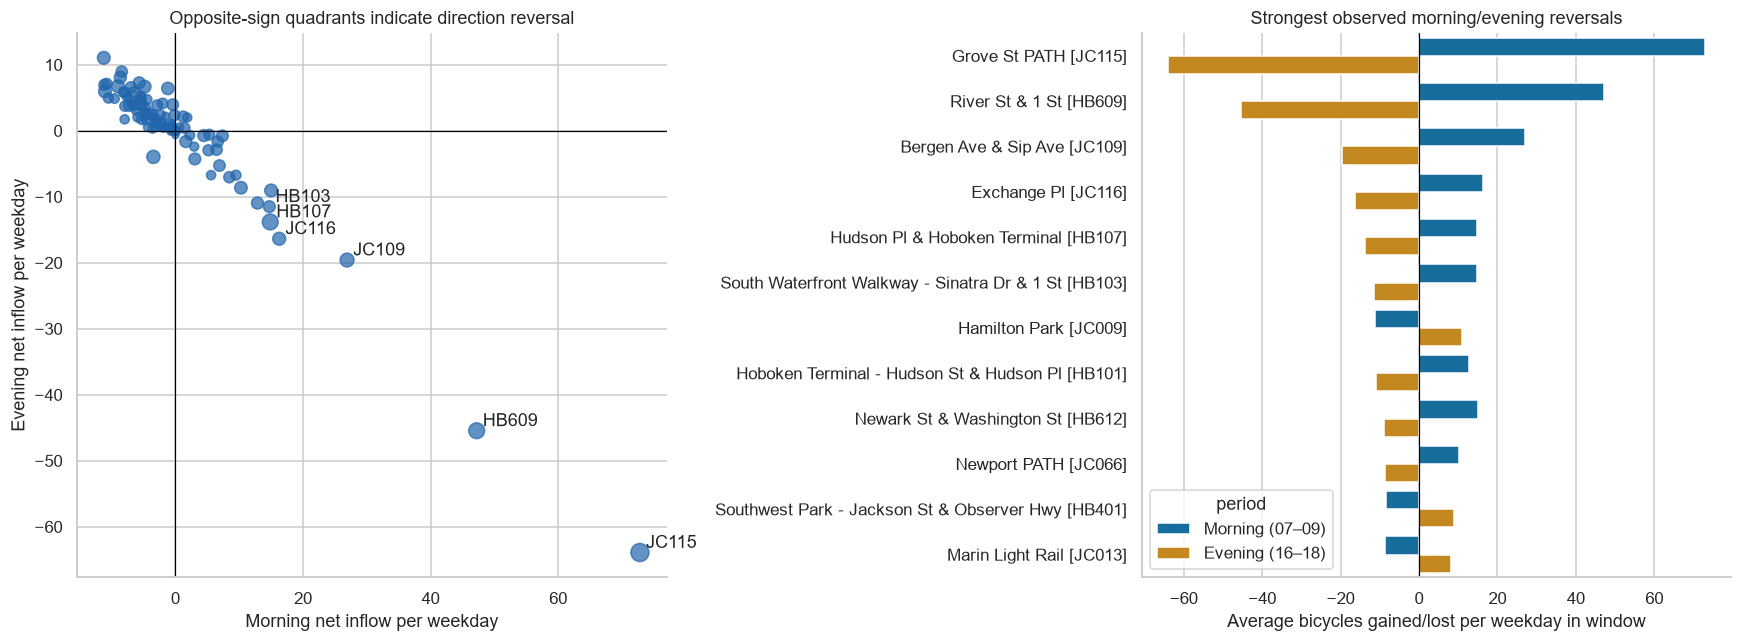

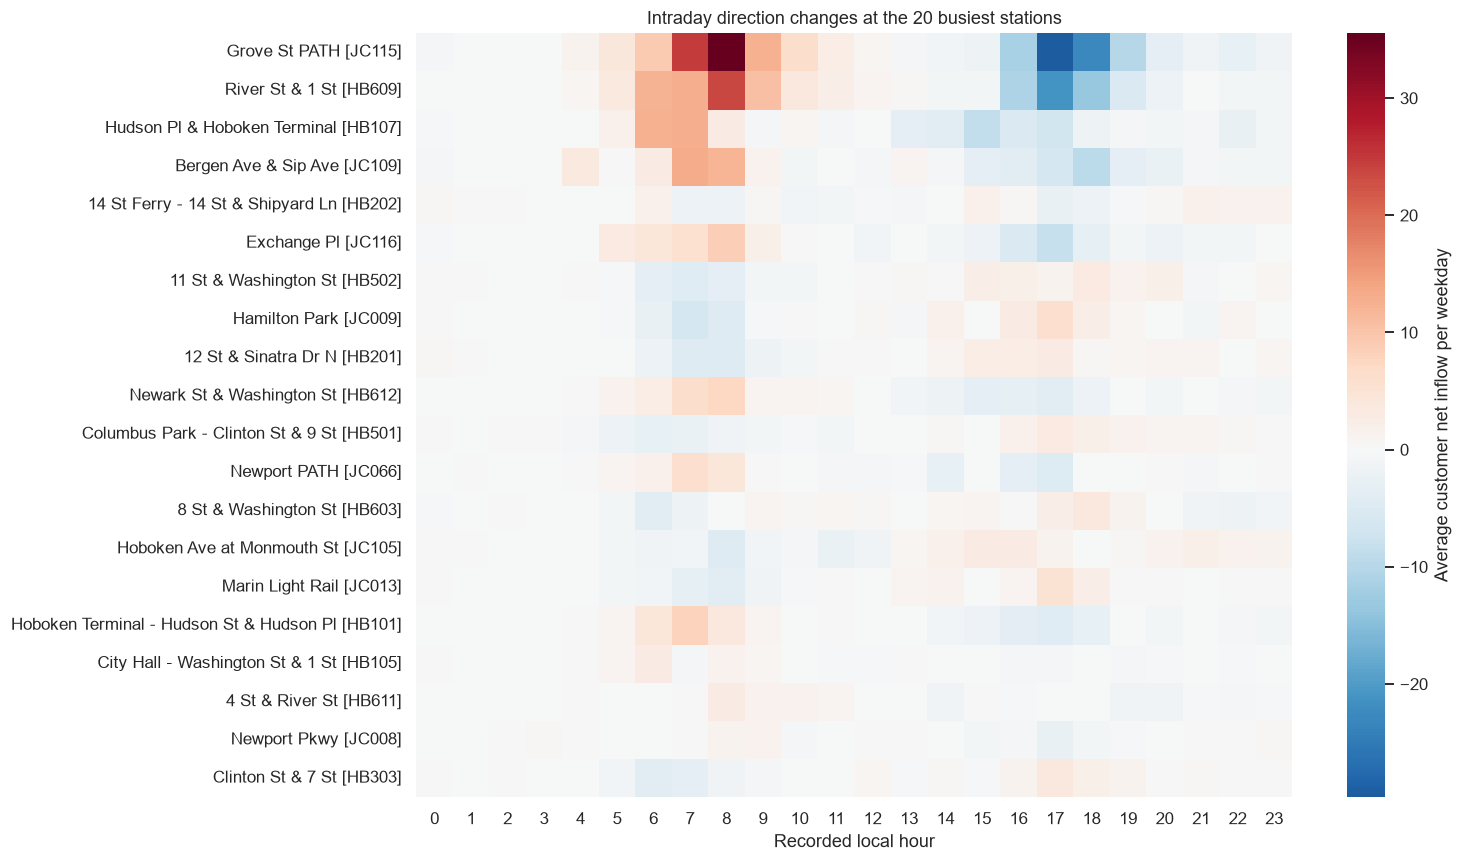

**Hypothesis check:** **96 of 108 stations** have opposite signs for average morning/evening net flow. Tiny sign changes are included, so rank by reversal magnitude and inspect the daily consistency below before selecting stations for the project.

In [8]:
weekday_grid = station_hourly[station_hourly['day_type'].eq('Weekday')]
windows = []
for period, hours in PERIOD_HOURS.items():
    p = weekday_grid[weekday_grid['hour'].isin(hours)].groupby('station_id')[['departures', 'arrivals', 'net_inflow']].sum()/day_counts['Weekday']
    p['period'] = period
    windows.append(p.reset_index())
window_flows = pd.concat(windows, ignore_index=True)
table_export(window_flows, 'weekday_peak_window_flows')
am_pm = window_flows.pivot(index='station_id', columns='period', values='net_inflow').reindex(LOCAL)
am_col, pm_col = list(PERIOD_HOURS)
am_pm['reversal'] = am_pm[am_col]*am_pm[pm_col] < 0
am_pm['reversal_magnitude'] = np.where(am_pm['reversal'], np.minimum(am_pm[am_col].abs(), am_pm[pm_col].abs()), 0)
am_pm['station_name'] = am_pm.index.map(canonical_names)
table_export(am_pm.reset_index(), 'morning_evening_reversal')
selected = am_pm['reversal_magnitude'].nlargest(12).index
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(am_pm[am_col], am_pm[pm_col], s=20+120*station_stats['total_activity'].reindex(am_pm.index)/station_stats['total_activity'].max(), color=BLUE, alpha=.7)
axes[0].axhline(0, color='black', linewidth=.8)
axes[0].axvline(0, color='black', linewidth=.8)
for sid in selected[:6]:
    axes[0].annotate(sid, (am_pm.loc[sid, am_col], am_pm.loc[sid, pm_col]), xytext=(4, 3), textcoords='offset points')
axes[0].set(xlabel='Morning net inflow per weekday', ylabel='Evening net inflow per weekday', title='Opposite-sign quadrants indicate direction reversal')
plot_windows = window_flows[window_flows['station_id'].isin(selected)].copy()
plot_windows['label'] = plot_windows['station_id'].map(dict(zip(selected, station_label(selected))))
sns.barplot(data=plot_windows, y='label', x='net_inflow', hue='period', order=station_label(selected), ax=axes[1])
axes[1].axvline(0, color='black', linewidth=.8)
axes[1].set(xlabel='Average bicycles gained/lost per weekday in window', ylabel='', title='Strongest observed morning/evening reversals')
savefig(fig, '08_morning_evening_reversal')
top20 = station_stats.nlargest(20, 'total_activity').index
net_hour = weekday_grid.groupby(['station_id', 'hour'])['net_inflow'].mean().unstack('hour').reindex(top20)
net_hour.index = station_label(net_hour.index)
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(net_hour, cmap='RdBu_r', center=0, ax=ax, cbar_kws={'label': 'Average customer net inflow per weekday'})
ax.set(xlabel='Recorded local hour', ylabel='', title='Intraday direction changes at the 20 busiest stations')
savefig(fig, '09_station_hour_net_flow')
say(f'**Hypothesis check:** **{int(am_pm["reversal"].sum())} of {len(LOCAL)} stations** have opposite signs for average morning/evening net flow. Tiny sign changes are included, so rank by reversal magnitude and inspect the daily consistency below before selecting stations for the project.')

## 8. Intraday inventory pressure and consistency across days
For each station/day, compute cumulative **observed** net inflow from zero. If $c_t$ is that cumulative change, then $\max(0,-\min_t c_t)$ is the opening-stock requirement to serve the recorded hourly departures in an idealized replay with no staff moves, no capacity limit and netting within each hour.

It is an **hourly-netted lower bound for this replay**, not actual opening stock or measured shortages. Within-hour ordering, missing endpoints, incoming trips absent from this extract and unobserved demand can change the requirement. The cumulative range $\max c_t-\min c_t$ measures inventory swing. Include the opening zero when computing extrema.

,station_id,mean_opening_lower_bound,p90_opening_lower_bound,mean_swing,max_swing,station_name
0,JC115,4.900000,14.2,78.900000,123,Grove St PATH
1,HB609,2.200000,8.1,58.533333,109,River St & 1 St
2,HB107,6.433333,19.2,33.633333,59,Hudson Pl & Hoboken Terminal
3,JC109,2.500000,8.1,32.033333,49,Bergen Ave & Sip Ave
4,JC116,4.166667,12.1,24.933333,50,Exchange Pl
5,HB612,3.333333,10.1,21.500000,29,Newark St & Washington St
6,HB103,4.833333,11.0,19.233333,40,South Waterfront Walkway - Sinatra Dr & 1 St
7,HB101,2.366667,7.1,18.933333,22,Hoboken Terminal - Hudson St & Hudson Pl
8,HB502,13.366667,21.0,17.400000,24,11 St & Washington St
9,JC105,12.933333,21.0,17.066667,28,Hoboken Ave at Monmouth St


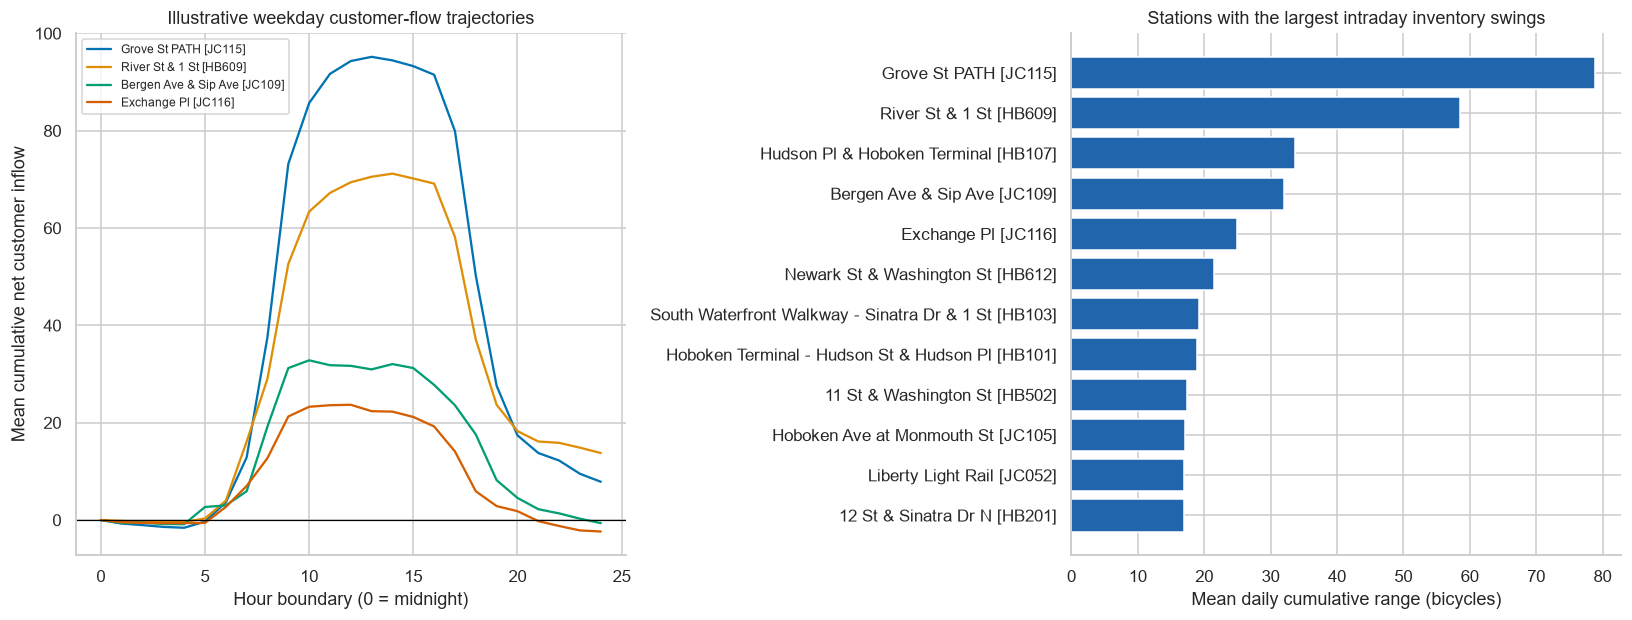

,station_id,mean,std,positive_day_share,negative_day_share,zero_day_share,station_name
0,JC115,72.818182,23.933711,1.000000,0.000000,0.000000,Grove St PATH
1,HB609,47.227273,19.937836,1.000000,0.000000,0.000000,River St & 1 St
2,JC109,26.909091,7.897613,1.000000,0.000000,0.000000,Bergen Ave & Sip Ave
3,JC116,16.272727,5.616149,0.954545,0.000000,0.045455,Exchange Pl
4,HB107,14.863636,5.986457,1.000000,0.000000,0.000000,Hudson Pl & Hoboken Terminal
5,HB103,14.727273,9.597529,0.863636,0.045455,0.090909,South Waterfront Walkway - Sinatra Dr & 1 St
6,JC009,-11.227273,6.125138,0.000000,0.863636,0.136364,Hamilton Park
7,HB101,12.863636,2.007022,1.000000,0.000000,0.000000,Hoboken Terminal - Hudson St & Hudson Pl
8,HB612,15.000000,6.015852,1.000000,0.000000,0.000000,Newark St & Washington St
9,JC066,10.272727,4.061220,0.954545,0.000000,0.045455,Newport PATH


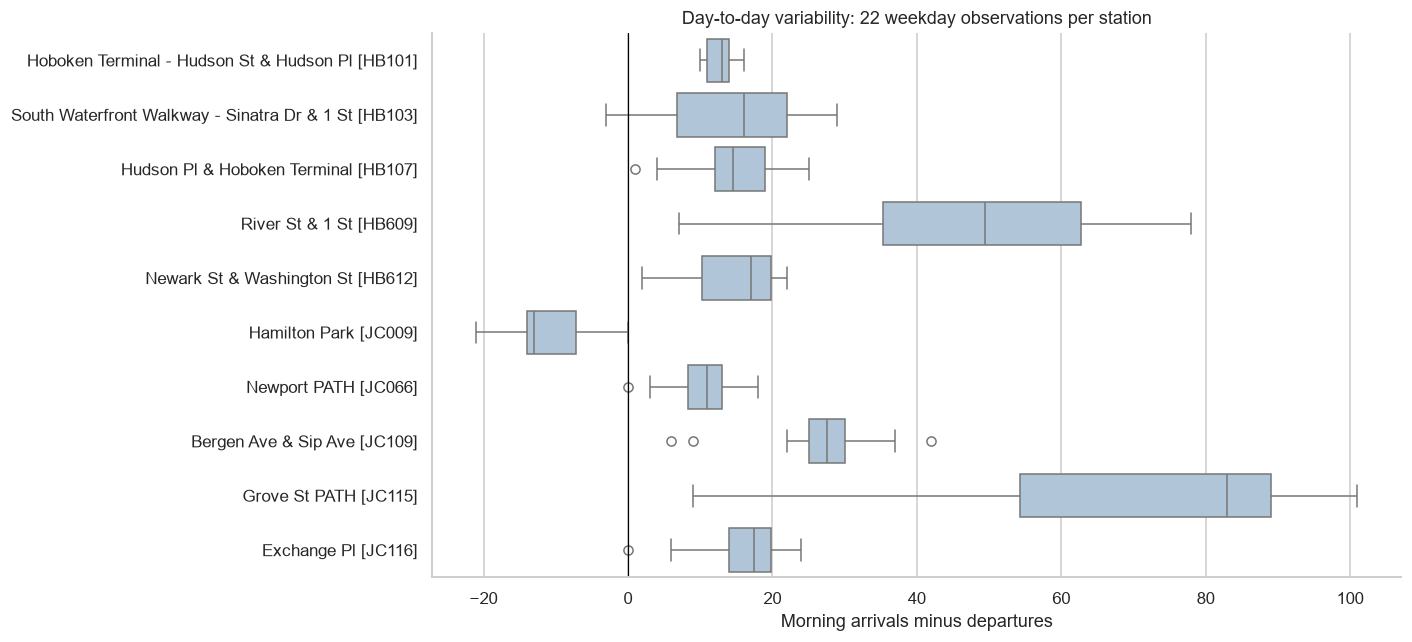

**Why this matters for OR:** daily variability supports comparing deterministic mean-flow plans with safety buffers or scenarios. The monthly net balance alone hides much of this intraday pressure. The curves describe recorded customer movements and must not be labeled actual station inventories.

In [9]:
station_hourly = station_hourly.sort_values(['station_id', 'hour_start'])
station_hourly['daily_cumulative_net_inflow'] = station_hourly.groupby(['station_id', 'date'])['net_inflow'].cumsum()
station_day = station_hourly.groupby(['station_id', 'date']).agg(
    departures=('departures', 'sum'), arrivals=('arrivals', 'sum'), net_inflow=('net_inflow', 'sum'),
    min_cumulative=('daily_cumulative_net_inflow', 'min'), max_cumulative=('daily_cumulative_net_inflow', 'max'))
station_day['min_cumulative'] = station_day['min_cumulative'].clip(upper=0)
station_day['max_cumulative'] = station_day['max_cumulative'].clip(lower=0)
station_day['opening_stock_lower_bound'] = -station_day['min_cumulative']
station_day['hourly_inventory_swing'] = station_day['max_cumulative'] - station_day['min_cumulative']
station_day = station_day.reset_index()
station_day['day_type'] = np.where(station_day['date'].dt.day_of_week < 5, 'Weekday', 'Weekend')
table_export(station_day, 'station_day_pressure')
pressure = station_day.groupby('station_id').agg(
    mean_opening_lower_bound=('opening_stock_lower_bound', 'mean'),
    p90_opening_lower_bound=('opening_stock_lower_bound', lambda s: s.quantile(.9)),
    mean_swing=('hourly_inventory_swing', 'mean'),
    max_swing=('hourly_inventory_swing', 'max'))
pressure['station_name'] = pressure.index.map(canonical_names)
display(table_export(pressure.sort_values('mean_swing', ascending=False).reset_index(), 'station_pressure_summary').head(12))
example_ids = list(am_pm['reversal_magnitude'].nlargest(4).index)
mean_curves = station_hourly[station_hourly['day_type'].eq('Weekday')].groupby(['station_id', 'hour'])['daily_cumulative_net_inflow'].mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for sid in example_ids:
    s = mean_curves.loc[sid]
    axes[0].plot(np.r_[0, s.index+1], np.r_[0, s.values], label=f'{canonical_names.get(sid, sid)} [{sid}]')
axes[0].axhline(0, color='black', linewidth=.8)
axes[0].set(xlabel='Hour boundary (0 = midnight)', ylabel='Mean cumulative net customer inflow', title='Illustrative weekday customer-flow trajectories')
axes[0].legend(fontsize=8, loc='best')
p = pressure.nlargest(12, 'mean_swing').sort_values('mean_swing')
axes[1].barh(station_label(p.index), p['mean_swing'], color=BLUE)
axes[1].set(xlabel='Mean daily cumulative range (bicycles)', title='Stations with the largest intraday inventory swings')
savefig(fig, '10_cumulative_flow_and_pressure')
# Daily direction reliability, including zero-event days, for the strongest reversal stations.
morning_daily = weekday_grid[weekday_grid['hour'].isin(PERIOD_HOURS[am_col])].groupby(['station_id', 'date'])['net_inflow'].sum()
morning_daily = morning_daily.rename('morning_net').reset_index()
reliability = morning_daily.groupby('station_id')['morning_net'].agg(
    mean='mean', std='std', positive_day_share=lambda s: s.gt(0).mean(),
    negative_day_share=lambda s: s.lt(0).mean(), zero_day_share=lambda s: s.eq(0).mean())
reliability['station_name'] = reliability.index.map(canonical_names)
display(table_export(reliability.reindex(selected).reset_index(), 'peak_station_daily_consistency'))
fig, ax = plt.subplots(figsize=(13, 6))
box = morning_daily[morning_daily['station_id'].isin(selected[:10])].copy()
box['label'] = box['station_id'].map(dict(zip(selected[:10], station_label(selected[:10]))))
sns.boxplot(data=box, y='label', x='morning_net', color='#a9c7df', ax=ax, showfliers=True)
ax.axvline(0, color='black', linewidth=.8)
ax.set(ylabel='', xlabel='Morning arrivals minus departures', title='Day-to-day variability: 22 weekday observations per station')
savefig(fig, '11_peak_day_variability')
say('**Why this matters for OR:** daily variability supports comparing deterministic mean-flow plans with safety buffers or scenarios. The monthly net balance alone hides much of this intraday pressure. The curves describe recorded customer movements and must not be labeled actual station inventories.')

## 9. Origin–destination demand and geographic structure
Popular customer routes help identify activity corridors. A redistribution vehicle often moves bicycles in the opposite direction of customer flows, but customer OD popularity alone does not determine its route. Routing needs a road travel-time matrix, vehicle/depot information and operating constraints.

,start_station_id_resolved,end_station_id_resolved,trips,origin_name,destination_name
3925,JC055,JC109,440,McGinley Square,Bergen Ave & Sip Ave
5770,JC109,JC055,420,Bergen Ave & Sip Ave,McGinley Square
5950,JC115,JC013,416,Grove St PATH,Marin Light Rail
68,HB101,JC105,399,Hoboken Terminal - Hudson St & Hudson Pl,Hoboken Ave at Monmouth St
3780,JC052,JC115,325,Liberty Light Rail,Grove St PATH
2707,JC013,JC115,319,Marin Light Rail,Grove St PATH
5964,JC115,JC052,307,Grove St PATH,Liberty Light Rail
234,HB107,HB201,291,Hudson Pl & Hoboken Terminal,12 St & Sinatra Dr N
5997,JC115,JC118,288,Grove St PATH,Pacific Ave & Communipaw Ave
5052,JC093,JC109,278,Fairmount Ave,Bergen Ave & Sip Ave


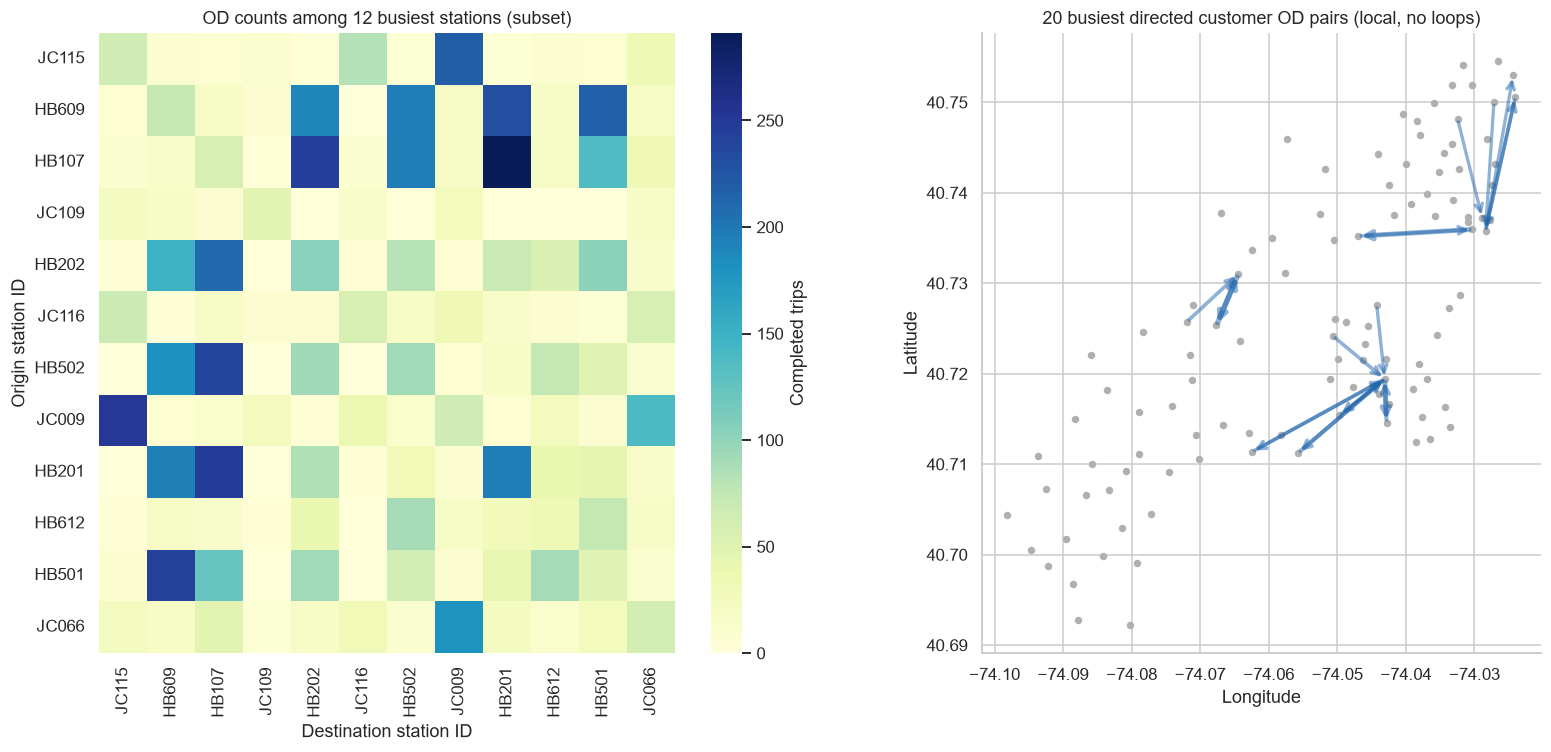

In [10]:
od = trips.dropna(subset=['start_station_id_resolved', 'end_station_id_resolved']).groupby(
    ['start_station_id_resolved', 'end_station_id_resolved']).size().rename('trips').reset_index()
od['origin_name'] = od['start_station_id_resolved'].map(canonical_names)
od['destination_name'] = od['end_station_id_resolved'].map(canonical_names)
table_export(od.sort_values('trips', ascending=False), 'observed_od_counts')
display(od.sort_values('trips', ascending=False).head(15))
top12 = station_stats.nlargest(12, 'total_activity').index
od_matrix = (od.pivot(index='start_station_id_resolved', columns='end_station_id_resolved', values='trips')
              .reindex(index=top12, columns=top12).fillna(0))
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.heatmap(od_matrix, cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Completed trips'})
axes[0].set(xlabel='Destination station ID', ylabel='Origin station ID', title='OD counts among 12 busiest stations (subset)')
axes[1].scatter(station_stats['lng'], station_stats['lat'], s=15, color='#b0b0b0')
local_od = od[od['start_station_id_resolved'].isin(LOCAL) & od['end_station_id_resolved'].isin(LOCAL) &
              od['start_station_id_resolved'].ne(od['end_station_id_resolved'])].nlargest(20, 'trips')
for r in local_od.itertuples():
    i, j = r.start_station_id_resolved, r.end_station_id_resolved
    if i not in station_coords.index or j not in station_coords.index:
        continue
    a, b = station_coords.loc[i], station_coords.loc[j]
    axes[1].annotate('', xy=(b['lng'], b['lat']), xytext=(a['lng'], a['lat']),
                     arrowprops={'arrowstyle': '->', 'color': BLUE, 'alpha': .5, 'lw': .5+3*r.trips/local_od['trips'].max()})
axes[1].set(xlabel='Longitude', ylabel='Latitude', title='20 busiest directed customer OD pairs (local, no loops)')
axes[1].set_aspect(1/np.cos(np.radians(40.73)))
savefig(fig, '12_od_structure')

## 10. Cleaning sensitivity and a small forecasting feasibility check
Sensitivity compares observed-flow summaries under alternative, clearly labeled inclusion rules. It does not choose the rule that gives the most attractive optimization result.

Before considering ML, compare a simple hourly mean baseline with a weekday/weekend hourly profile. Train on **1–20 September** and evaluate on **21–30 September**. Both predict **completed station departures**, not unconstrained demand. Station-hours with zero recorded departures are included. The split contains little history; it is an exploratory check, not model selection evidence or a seasonal forecast.

,scenario,september_starts,local_departures,local_arrivals,sum_absolute_monthly_station_net,unresolved_september_arrivals
0,"Primary: valid events, name recoveries, long trips retained",106617,106617,106070,2493,284
1,Exclude >24-hour trips (review scenario),106581,106581,106069,2482,248
2,No station-ID recovery,106617,106617,106021,2522,333
3,September starts only (drops carry-in arrivals),106617,106617,106061,2498,282


,method,station_hour_MAE,station_hour_RMSE,bias_predicted_minus_actual,test_station_hours
0,Station + hour average,0.969248,1.663146,0.224479,25920
1,Station + day type + hour average,0.899465,1.495344,0.251211,25920


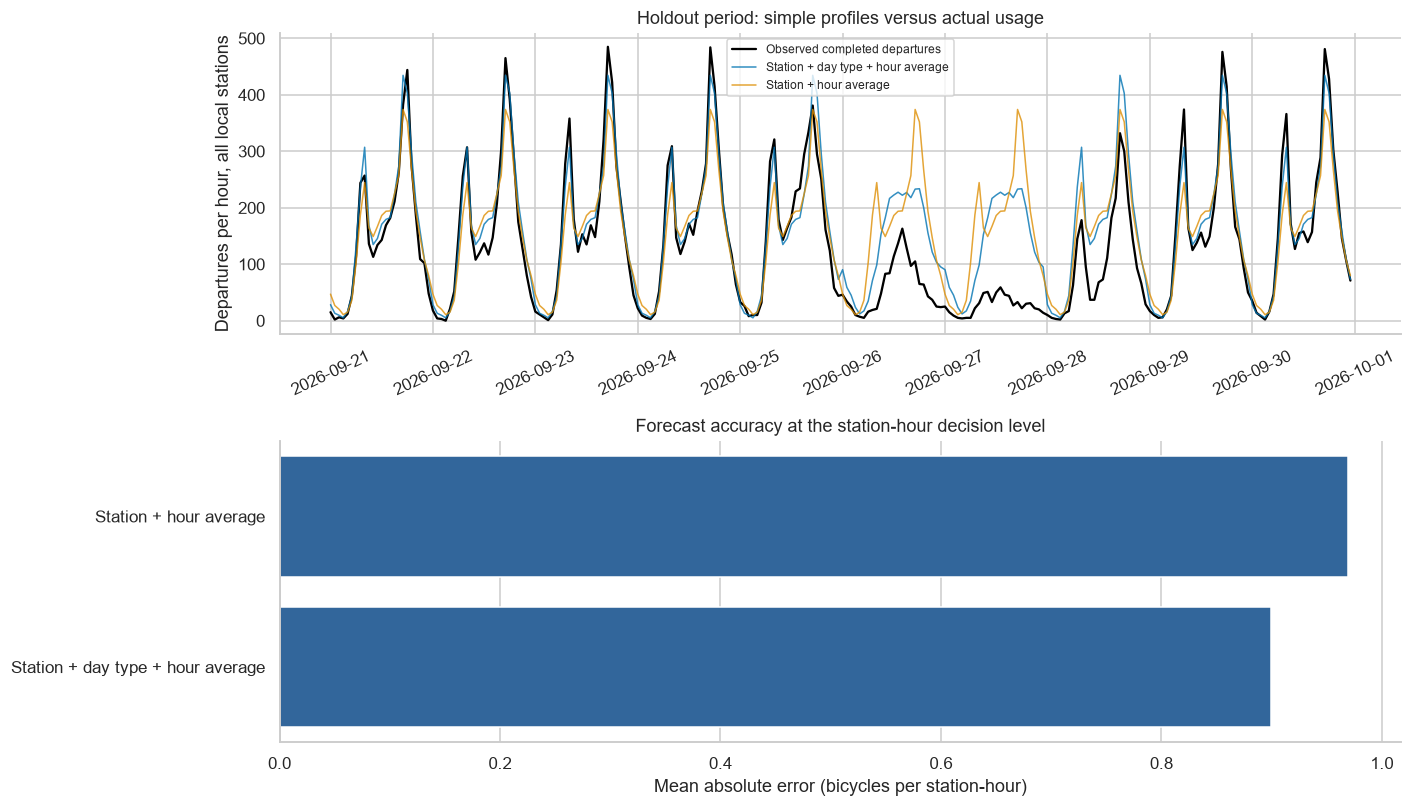

**Modeling implication:** one month gives only a few observations of each weekday/hour combination. Start with transparent demand profiles or day scenarios. Add ML only if it improves chronological holdout accuracy **and** the resulting redistribution decisions. A low average error across many quiet station-hours can mask errors at busy stations, so inspect peaks separately.

,method,peak_station_hour_MAE
0,Station + day type + hour average,1.311420
1,Station + hour average,1.511559


In [11]:
def flow_sensitivity(label, mask, use_original_ids=False):
    f = df.loc[mask].copy()
    if use_original_ids:
        for side in ['start', 'end']:
            f[f'{side}_station_id_resolved'] = f[f'{side}_station_id']
    e = make_events(f)
    local = e[e['station_id'].isin(LOCAL)]
    balance = local.groupby('station_id')['delta'].sum().reindex(LOCAL, fill_value=0)
    return {'scenario': label,
            'september_starts': int((f['started_at_parsed'].ge(MONTH_START) & f['started_at_parsed'].lt(MONTH_END)).sum()),
            'local_departures': int(local['event'].eq('departure').sum()),
            'local_arrivals': int(local['event'].eq('arrival').sum()),
            'sum_absolute_monthly_station_net': int(balance.abs().sum()),
            'unresolved_september_arrivals': int((e['event'].eq('arrival') & e['station_id'].isna()).sum())}

sensitivity = pd.DataFrame([
    flow_sensitivity('Primary: valid events, name recoveries, long trips retained', valid_trip),
    flow_sensitivity('Exclude >24-hour trips (review scenario)', valid_trip & ~df['flag_long_ride']),
    flow_sensitivity('No station-ID recovery', valid_trip, use_original_ids=True),
    flow_sensitivity('September starts only (drops carry-in arrivals)', valid_trip & df['start_in_month']),
])
display(table_export(sensitivity, 'cleaning_sensitivity'))

train_end = pd.Timestamp('2026-09-21')
train = station_hourly[station_hourly['hour_start'] < train_end].copy()
test = station_hourly[station_hourly['hour_start'] >= train_end].copy()
forecast_metrics, forecast_rows = [], []
for method, keys in [('Station + hour average', ['station_id', 'hour']),
                      ('Station + day type + hour average', ['station_id', 'day_type', 'hour'])]:
    means = train.groupby(keys)['departures'].mean().rename('predicted_departures').reset_index()
    pred = test.merge(means, on=keys, how='left', validate='many_to_one')
    if pred['predicted_departures'].isna().any():
        raise ValueError('Forecast grouping absent in training; add an explicit fallback.')
    err = pred['predicted_departures'] - pred['departures']
    forecast_metrics.append({'method': method, 'station_hour_MAE': err.abs().mean(),
                              'station_hour_RMSE': np.sqrt((err**2).mean()),
                              'bias_predicted_minus_actual': err.mean(), 'test_station_hours': len(pred)})
    pred['method'] = method
    forecast_rows.append(pred[['station_id', 'hour_start', 'departures', 'predicted_departures', 'method']])
forecast_metrics = pd.DataFrame(forecast_metrics)
forecasts = pd.concat(forecast_rows, ignore_index=True)
display(table_export(forecast_metrics, 'forecast_baseline_metrics'))
table_export(forecasts, 'forecast_holdout_predictions')
observed_totals = test.groupby('hour_start')['departures'].sum()
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5))
axes[0].plot(observed_totals.index, observed_totals, color='black', linewidth=1.5, label='Observed completed departures')
for method, group in forecasts.groupby('method'):
    p = group.groupby('hour_start')['predicted_departures'].sum()
    axes[0].plot(p.index, p, alpha=.8, linewidth=1, label=method)
axes[0].set(ylabel='Departures per hour, all local stations', title='Holdout period: simple profiles versus actual usage')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=25)
sns.barplot(data=forecast_metrics, x='station_hour_MAE', y='method', color=BLUE, ax=axes[1])
axes[1].set(xlabel='Mean absolute error (bicycles per station-hour)', ylabel='', title='Forecast accuracy at the station-hour decision level')
savefig(fig, '13_forecast_feasibility')
say('**Modeling implication:** one month gives only a few observations of each weekday/hour combination. Start with transparent demand profiles or day scenarios. Add ML only if it improves chronological holdout accuracy **and** the resulting redistribution decisions. A low average error across many quiet station-hours can mask errors at busy stations, so inspect peaks separately.')
peak_test = test[test['hour'].isin([7, 8, 9, 16, 17, 18])].copy()
peak_keys = pd.MultiIndex.from_frame(peak_test[['station_id', 'hour_start']])
peak_metrics = []
for method, group in forecasts.groupby('method'):
    mask = pd.MultiIndex.from_frame(group[['station_id', 'hour_start']]).isin(peak_keys)
    g = group.loc[mask]
    peak_metrics.append({'method': method, 'peak_station_hour_MAE': (g['predicted_departures']-g['departures']).abs().mean()})
display(table_export(pd.DataFrame(peak_metrics), 'forecast_peak_metrics'))

## 11. What project paths does the evidence support?

| Path | Decision and method | Course link | What is needed / how to evaluate |
|---|---|---|---|
| **Recommended starting point: static redistribution** | Bicycles moved between stations before an explicit peak window; transportation / min-cost flow LP | Lecture6 network flow; Lecture4 duality and sensitivity | State initial stock, target stock, capacity and per-bike transfer-cost assumptions. Compare no moves, greedy nearest surplus-to-deficit and LP under identical assumptions and budget. |
| **Strong extension: time-expanded redistribution** | When and where to relocate, with hourly stock conservation and delayed vehicle arrivals | Lecture6 time-expanded containers; inventory balances in Assignment3 Q5 | Need initial inventory, dock capacity and relocation timing. Evaluate recorded-flow replay with assumed availability; report proxy outcomes, not measured avoided lost demand. |
| **Uncertainty extension: scenario optimization** | First-stage repositioning followed by scenario-specific rentals/returns or corrective transfers; SAA | Lecture7 slides 19–20; Assignment3 Q1–2; Lecture5 robustness | Use training-day demand scenarios, preserving joint station/time dependence. Hold out later days. Compare expected cost, lower-tail service and budgets. The same first-stage decision must apply to every scenario. |
| **Routing extension: MIP / vehicle routing** | Truck visits, pickup/delivery amounts and route order | Lecture7 binary models, TSP, LP bounds and branch-and-bound | Requires depot, truck load/capacity, shift length and road travel times. Start with a small station subset. Report incumbent, bound, MIP gap and runtime. |
| **ML + OR, optional** | Forecast station departures/arrivals, then optimize redistribution | Forecast inputs feed the above OR models | Obtain more months and, if available, weather/calendar/availability covariates. Compare simple profiles against count models or tree models with chronological validation. Measure downstream operating cost/service, not only forecast MAE. |
| **ML alone** | Predict recorded trip counts or cluster station profiles | Useful EDA/support, weaker match to this paper's prescriptive purpose | Does not itself answer how many bicycles to relocate. Use as support for an explicit decision problem rather than the entire project. |

**Proposed research question:** How much can a budget-limited redistribution plan reduce inventory pressure during observed peak periods, and how sensitive is its performance to uncertain flows and operating assumptions?

**Recommended sequence:** validate station flows → define a small, transparent baseline LP → compare no redistribution and a greedy policy → vary fleet/budget, costs, target buffer and demand scenarios → add time expansion or uncertainty if the baseline is sound. Truck routing and ML are optional extensions. No optimization results are claimed by this EDA.

### A concrete first LP, with assumptions separated from observations
Let $I_i$ be **assumed or separately obtained** opening stock, $b_i$ a target derived from training data, $C_i$ dock capacity, $c_{ij}$ an assumed/measured cost per relocated bicycle, and $B$ a relocation limit. Decide relocations $x_{ij}\geq0$ and target shortfalls $s_i\geq0$:

$$\min\ \sum_{(i,j)\in A} c_{ij}x_{ij}+p\sum_i s_i$$
$$J_i=I_i+\sum_jx_{ji}-\sum_jx_{ij},\quad 0\leq J_i\leq C_i,\quad J_i+s_i\geq b_i,$$
$$\sum_jx_{ij}\leq I_i,\qquad \sum_{i,j}x_{ij}\leq B.$$

Here $J_i$ is post-relocation stock and $s_i$ is **target shortfall**, not measured unmet rental demand. The outbound constraint assumes simultaneous transfers supplied from original stock. The basic uncapacitated target should be checked against $C_i$ rather than hidden by clipping. The per-bike cost omits truck routing/fixed dispatch charges. All numbers not present in the trip file must be labeled assumptions and varied.

A pure transportation/min-cost-flow formulation has integral extreme points with integral supplies/capacities, so an LP can be enough. **Additional constraints can destroy this property**; do not assume the displayed extended model or a distance-budget model is automatically integral. Integer bicycles can instead be enforced with a MIP when required. Fixed truck activation and routing require binary decisions, increasing difficulty.

**Algorithmic thinking:** simplex moves between BFSs; transportation bases relate to spanning trees. Network algorithms exploit structure. An LP relaxation provides a bound for a MIP; branch-and-bound closes the gap. Time expansion gives a large structured LP, whereas exact DP over inventory at every station has a state space roughly $\prod_i(C_i+1)$ and is unsuitable for a full 108-station problem. LP dual values can explain marginal resources within validity ranges; they are not automatically shadow prices for discrete truck decisions. These distinctions give a course-grounded paper without implementing every algorithm from scratch.

### Data needed before claiming actual service improvements
- Historical station inventories and dock capacities aligned to September, including outages/maintenance and electric-bike restrictions if relevant.
- Initial fleet distribution, staff relocation logs, depots, truck fleet/capacity, loading times and costs.
- A road travel-time/distance matrix; straight-line distance is only a labeled approximation for sensitivity work.
- More historical months for forecasting/seasonal robustness and station changes.
- Unsuccessful rental/return information or an explicit model of censored demand.

Current GBFS station/status feeds can describe current conditions or support future collection. They do **not** reconstruct September 2026 inventory histories. If those histories are unavailable, frame the project as a transparent scenario study calibrated to observed flows. Electric/classic bike substitution and charging need extra assumptions; keep the baseline pooled or restrict its scope explicitly.

**Reference-book reading map:** the local Hillier/Lieberman PDF is the **seventh edition (2001)**: chapters 8–9 for transportation/network models, 11 for DP, 12 for IP and 22 for simulation. Bradley/Hax/Magnanti has chapter 8 on networks, 9 on IP and 11 on DP. Bertsimas/Tsitsiklis (1997), supplied chapters 1–5, supports LP geometry, simplex, duality and sensitivity. Cite the edition actually supplied, and check the relevant original pages when developing the model.

In [12]:
# Reconciliations are independent of chart formatting and guard the key data definitions.
assert len(raw) == len(df) + exact_duplicates
assert len(trips) == int((valid_trip & df['start_in_month']).sum())
assert len(station_hourly) == len(LOCAL)*len(HOURS)
assert not station_hourly.duplicated(['station_id', 'hour_start']).any()
assert int(station_hourly['departures'].sum()) == int((local_events['event'] == 'departure').sum())
assert int(station_hourly['arrivals'].sum()) == int((local_events['event'] == 'arrival').sum())
assert int(events['delta'].sum()) == int(events['event'].eq('arrival').sum()-events['event'].eq('departure').sum())
assert np.array_equal(station_hourly['net_inflow'].to_numpy(), (station_hourly['arrivals']-station_hourly['departures']).to_numpy())
assert not set(train['hour_start']).intersection(set(test['hour_start']))
assert len(forecasts) == len(test)*2
assert station_day['hourly_inventory_swing'].ge(0).all()

manifest = {
    'source_relative_path': str(SOURCE.relative_to(ROOT)), 'source_sha256': source_hash,
    'raw_rows': len(raw), 'valid_september_starts': len(trips), 'columns': list(raw.columns),
    'observed_origin_stations': int(df['start_station_id'].nunique()),
    'observed_destination_stations': int(df['end_station_id'].nunique()), 'service_domain_stations': len(LOCAL),
    'missing_end_ids_raw': int(df['end_station_id'].isna().sum()),
    'recovered_end_ids': int(df['end_id_recovered'].sum()),
    'unresolved_end_ids': int(df['end_station_id_resolved'].isna().sum()),
    'outside_domain_arrivals': outside_count, 'long_trips': int(df['flag_long_ride'].sum()),
    'out_of_month_starts': int((valid_trip & ~df['start_in_month']).sum()),
    'recorded_timestamp_timezone': 'Unspecified in CSV; analyzed as recorded local clock time',
    'analysis_month_start': str(MONTH_START), 'analysis_month_end_exclusive': str(MONTH_END),
    'peak_windows_hours': PERIOD_HOURS, 'september_weekdays': int(day_counts['Weekday']),
    'september_weekend_days': int(day_counts['Weekend']), 'station_hours': len(station_hourly),
    'morning_evening_reversal_stations': int(am_pm['reversal'].sum()),
    'member_share_pct': member_share, 'electric_share_pct': electric_share,
    'median_duration_min': float(trips['duration_min'].median()),
    'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
    'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
    'validation': 'All reconciliation assertions passed',
}
(OUT / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
requirements = f'pandas=={pd.__version__}\nnumpy=={np.__version__}\nmatplotlib=={matplotlib.__version__}\nseaborn=={sns.__version__}\nnbformat\nnbclient\nipykernel\n'
(OUT / 'requirements.txt').write_text(requirements, encoding='utf-8')

top_loss = station_stats['net_inflow'].idxmin()
top_gain = station_stats['net_inflow'].idxmax()
strongest = am_pm['reversal_magnitude'].idxmax()
def md_table(frame, columns=None):
    f = frame if columns is None else frame[columns]
    def fmt(v):
        return f'{v:.3f}' if isinstance(v, (float, np.floating)) else str(v).replace('|', '/')
    return '| ' + ' | '.join(f.columns) + ' |\n| ' + ' | '.join(['---']*len(f.columns)) + ' |\n' + '\n'.join('| ' + ' | '.join(fmt(v) for v in r) + ' |' for r in f.itertuples(index=False, name=None))

report = f'''# Citi Bike EDA findings and project options

This analysis uses the supplied local trip file. Start with `CitiBike_JC_202609_EDA.ipynb` for the code, explanations and 13 figure panels. The source CSV is unchanged. The source hash and software versions are in `analysis_manifest.json`.

## Data coverage and cleaning

- Raw file: **{len(raw):,} trips**, 13 fields. **{len(trips):,} valid September-start trips** after the declared time rules.
- **{df['start_station_id'].nunique()} origin IDs, {df['end_station_id'].nunique()} destination IDs**, {endpoints['station_id'].nunique()} in the union. The service domain is the {len(LOCAL)} observed JC/HB origin stations.
- **{int(df['end_station_id'].isna().sum()):,} blank destination IDs** originally. **{int(df['end_id_recovered'].sum()):,}** recovered using unique exact-name matches; **{int(df['end_station_id_resolved'].isna().sum()):,}** remain unresolved. Recovered IDs are flagged. Coordinates are not filled.
- **{int((valid_trip & ~df['start_in_month']).sum()):,} starts outside September**. Their September arrivals remain in the event view.
- **{exact_duplicates:,} exact duplicate rows**, **{len(conflict_ids):,} conflicting ride IDs**; **{int(df['flag_nonpositive_duration'].sum()):,} nonpositive durations**.
- **{int(df['flag_long_ride'].sum()):,} trips over 24 hours** are flagged and retained, with a sensitivity comparison. No automatic outlier winsorization/deletion.
- Among September starts, **{long_unresolved} of {int(trips['flag_long_ride'].sum())} trips over 24 hours have unresolved end IDs**. Missingness and extreme duration are associated, so complete-case deletion can distort the duration profile. No cause is assumed.
- **{outside_count:,} known outside-domain arrivals**. Missing destinations and external endpoints prevent treating this as a fully observed closed system.
- Timestamps have no timezone metadata. Analyze clock times as recorded; no Singapore conversion. Calendar weekdays include holidays.

## Observed patterns

- Member share: **{member_share:.1f}%**; electric-bike share: **{electric_share:.1f}%**; median duration: **{trips['duration_min'].median():.2f} min**.
- Three highest average weekday departure hours: **{', '.join(str(int(h))+':00' for h in weekday_peak['hour'])}**.
- Daily September-start counts range from **{daily['departures'].min():,} on {daily['departures'].idxmin():%d %b}** to **{daily['departures'].max():,} on {daily['departures'].idxmax():%d %b}**. Investigate causes; low days are not deleted.
- **{int(am_pm['reversal'].sum())}/{len(LOCAL)} stations** reverse the sign of average net flow between 07:00–09:59 and 16:00–18:59 on weekdays. Tiny reversals count; inspect magnitude and daily consistency.
- Largest monthly observed net outflow: **{canonical_names.get(top_loss, top_loss)} [{top_loss}], {station_stats.loc[top_loss, 'net_inflow']:+,}**. Largest net inflow: **{canonical_names.get(top_gain, top_gain)} [{top_gain}], {station_stats.loc[top_gain, 'net_inflow']:+,}**.
- Strongest minimum-magnitude AM/PM reversal: **{canonical_names.get(strongest, strongest)} [{strongest}]**, morning **{am_pm.loc[strongest, am_col]:+.1f}**, evening **{am_pm.loc[strongest, pm_col]:+.1f} bicycles per weekday**.

These are descriptive patterns consistent with directional commuting. Trip purpose, empty/full stations and actual lost rentals are not observed. Cumulative net-flow graphs are not actual inventory trajectories.

## Recommended project direction

Lead with **optimization**. Start with a peak-window transportation/min-cost-flow redistribution model, then test a time-expanded or scenario-based extension if feasible. Compare no redistribution, a budget-matched greedy surplus-to-deficit policy and the optimized policy using identical stock/capacity/cost assumptions and held-out days.

The question could be: **How much can budget-limited bicycle redistribution reduce peak-period inventory pressure, and how robust is that plan to uncertain flows and operating assumptions?**

1. **LP/network flow:** strongest baseline connection to Lecture6. Decide bicycle transfers and target shortfalls. Study relocation limits, target buffers and cost sensitivity. Pure network structure supports LP integrality with integral data; do not assume extensions preserve it.
2. **Time-expanded LP:** model hourly inventory conservation and transfer timing, drawing on the container example in Lecture6. Initial stock, station capacity and transit lead times need evidence or labeled assumptions.
3. **Stochastic/SAA or robust optimization:** directly related to Lecture5, Lecture7 slides19–20 and Assignment3 Q1–2. Preserve dependence by using joint day scenarios. Use common first-stage decisions and held-out evaluation.
4. **Truck-routing MIP:** optional and substantially harder. Need road times, depots, truck capacities, shifts and loading times. Begin with a small station subset. Report bounds, gaps and runtime, not merely a route.
5. **ML + optimization:** optional forecasting layer, not required for a strong OR paper. Compare transparent profiles with count/tree models only after obtaining enough history. Evaluate both forecasting accuracy and downstream decision value. Full-network inventory DP has an impractically large state space.

## Exploratory forecasting check

Train 1–20 September; evaluate 21–30 September. Target: recorded station-hour departures, including zero-event hours. This is a small holdout, not robust evidence of seasonal generalization. Only these transparent forecasting baselines are fitted; no advanced ML model is included.

{md_table(forecast_metrics)}

## Missing inputs and claims to avoid

Trip records do not contain station capacities, initial stocks, redistribution logs, failed rentals/returns, truck costs or availability. Shortage reductions therefore need additional data or a clearly labeled simulation model. Current GBFS cannot reconstruct September inventory histories. Straight-line separation is not road/truck distance. Observed demand can be constrained by availability, and incoming boundary trips outside this extract may be missing. One month cannot establish annual seasonality or weather causation.

## Main files

- Notebook and matching Python script in the project root.
- `data_quality.csv`, `cleaning_audit.csv`, `flagged_records.csv`, `cleaning_sensitivity.csv` document data handling.
- `cleaned_september_trips.csv` preserves original columns plus parsed/resolved fields and flags.
- `station_hourly_observed_flows.csv` has a complete {len(LOCAL)} × {len(HOURS)} grid; `station_day_pressure.csv` gives replay proxies, not measured shortages.
- `station_summary.csv`, `weekday_peak_window_flows.csv`, `morning_evening_reversal.csv`, `observed_od_counts.csv`, and forecasting tables support later modeling.
- `figures/` contains the 13 PNG panels, also embedded in the notebook.

## Source references

- Supplied local CSV: `{SOURCE.relative_to(ROOT)}`. Every empirical number above is computed from it.
- [Official Citi Bike system-data description](https://citibikenyc.com/system-data), accessed 13 November 2026: field definitions and pointer to GBFS. No external data merged.
- Local `Lecture4 DualitySensitivity.pdf`, slides24–41; `Lecture5 LPCases.pdf`; `Lecture6 Network.pdf`, slides17–29 and44–61; `Lecture7 IP.pdf`, slides14–37 and63–79; `Lecture8 DP.pdf`; `Assignment_3.pdf`, Q1–2; and `Project_Guideline.pdf`, pp1–4.
- Reference-book map: local Hillier/Lieberman, seventh edition (2001), chapters8–9,11–12,22; Bradley/Hax/Magnanti chapters8,9,11; Bertsimas/Tsitsiklis (1997), supplied chapters1–5. These support the stated model families; verify original passages when writing the final paper.

The guideline emphasizes a clear model, defensible methodology, sensitivity/limitations and interpretation. It permits an applied problem with explicit assumptions; a machine-learning component is not necessary.
'''
(OUT / 'EDA_Findings_and_Project_Options.md').write_text(report, encoding='utf-8')
say(f'**Complete:** 13 figure panels, cleaning and flow tables, an analysis manifest and a written project-options summary are saved under `{OUT.relative_to(ROOT)}`. All reconciliation checks passed. No optimization solution or actual shortage estimate is claimed.')

**Complete:** 13 figure panels, cleaning and flow tables, an analysis manifest and a written project-options summary are saved under `output\citibike_eda`. All reconciliation checks passed. No optimization solution or actual shortage estimate is claimed.